<img src="https://uwe-cyber.github.io/images/uwe_banner.png">

# UFCFEL-15-3 Security Data Analytics and Visualisation
## Portfolio Assignment: Part 3
### Academic year: 2025-26

## Conduct a security investigation into a suspected insider threat
---

**UWEtech** are calling you back once more to help them with their security challenges. They believe that one of their employees has been the cause of their recent security problems, and they believe they may have an insider threat within the company. They enlist your help to examine employee log activity, to see what behaviours deviate from the norm and to identify which user may be acting as a threat to their organisation.

**Dataset:** You will be issued a **unique dataset** based on your UWE student ID. **Failure to use the dataset that corresponds to your student ID will result in zero marks.** Please access the datasets via Blackboard.

**This exercise carries a weight of 45% towards your overall portfolio submission**


### Submission Documents
---

For Part 3 of your portfolio, your complete output file should be saved as:

- **STUDENT_ID-PART3.ipynb**

This should then be included in a ZIP file along with your other two portfolio documents.

The deadline for your portfolio submission is **THURSDAY 11th DECEMBER @ 14:00**. 

## DATASET: Load in the data

**Please provide the string below that you have been assigned as given in the spreadsheet available on Blackboard. The directory containing your dataset should be at the same location as your notebook file.**

In [2]:
# PLEASE ENTER THE NAME OF THE DATASET ASSIGNED TO YOU AS INDICATED ON BLACKBOARD
DATASET = 'QuantumLockSystems'

### Function for loading data - do not change

In [3]:
import random
import string
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import datetime

def load_data(DATASET):
    dataset_list = ['QuantumLockSystems', 'uwetech-dataset02', 'uwetech-dataset03', 'uwetech-dataset04',
                    'CodeCraftersInc', 'CyberCoreEnterprises', 'SynapseTechInnovations', 'VirtuGuardSystems', 'QuantumLockSystems']
    if DATASET in dataset_list:
        email_data = pd.read_csv('./' + DATASET + '/email_data.csv', parse_dates=True, index_col=0)
        file_data = pd.read_csv('./' + DATASET + '/file_data.csv', parse_dates=True, index_col=0)
        web_data = pd.read_csv('./' + DATASET + '/web_data.csv', parse_dates=True, index_col=0)
        login_data = pd.read_csv('./' + DATASET + '/login_data.csv', parse_dates=True, index_col=0)
        usb_data = pd.read_csv('./' + DATASET + '/usb_data.csv', parse_dates=True, index_col=0)
        employee_data = pd.read_csv('./' + DATASET + '/employee_data.csv', index_col=0)
        
        email_data['datetime'] = pd.to_datetime(email_data['datetime'])
        file_data['datetime'] = pd.to_datetime(file_data['datetime'])
        web_data['datetime'] = pd.to_datetime(web_data['datetime'])
        login_data['datetime'] = pd.to_datetime(login_data['datetime'])
        usb_data['datetime'] = pd.to_datetime(usb_data['datetime'])
    else:
        print ("DATASET variable not defined - please refer to Blackboard for DATASET name")
        return
    return employee_data, login_data, usb_data, web_data, file_data, email_data

employee_data, login_data, usb_data, web_data, file_data, email_data = load_data(DATASET)

C:\Users\Chiko\AppData\Local\Temp\ipykernel_22232\521939007.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  email_data = pd.read_csv('./' + DATASET + '/email_data.csv', parse_dates=True, index_col=0)
C:\Users\Chiko\AppData\Local\Temp\ipykernel_22232\521939007.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  file_data = pd.read_csv('./' + DATASET + '/file_data.csv', parse_dates=True, index_col=0)
C:\Users\Chiko\AppData\Local\Temp\ipykernel_22232\521939007.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  web_data = pd.read_csv('./' + DATASET + '/web_data.csv', pa

### The following code samples may be useful to aid your investigation

In [4]:
# This shows the employee_data DataFrame
employee_data

,user,role,email,pc
0,usr-xvz,Security,usr-xvz@QuantumLockSystems.com,pc0
1,usr-eiv,Legal,usr-eiv@QuantumLockSystems.com,pc1
2,usr-dks,Services,usr-dks@QuantumLockSystems.com,pc2
3,usr-ann,Services,usr-ann@QuantumLockSystems.com,pc3
4,usr-dek,Director,usr-dek@QuantumLockSystems.com,pc4
...,...,...,...,...
95,usr-zme,HR,usr-zme@QuantumLockSystems.com,pc95
96,usr-xeq,Finance,usr-xeq@QuantumLockSystems.com,pc96
97,usr-tqq,Finance,usr-tqq@QuantumLockSystems.com,pc97
98,usr-ins,Services,usr-ins@QuantumLockSystems.com,pc98


In [5]:
# This shows the login_data DataFrame
login_data

,datetime,user,action,pc
0,2024-01-01 07:28:26,usr-xvz,login,pc0
1,2024-01-01 14:45:43,usr-xvz,logoff,pc0
2,2024-01-01 09:52:29,usr-eiv,login,pc1
3,2024-01-01 17:55:05,usr-eiv,logoff,pc1
4,2024-01-01 06:16:00,usr-dks,login,pc2
...,...,...,...,...
36395,2024-06-30 17:37:40,usr-tqq,logoff,pc97
36396,2024-06-30 06:51:39,usr-ins,login,pc98
36397,2024-06-30 15:53:54,usr-ins,logoff,pc98
36398,2024-06-30 07:44:07,usr-rgt,login,pc99


In [6]:
# This shows how to filter the login_data DataFrame by a particular username
login_data[login_data['user']=='usr-nic']

,datetime,user,action,pc


In [7]:
# This shows how to filter the login_data DataFrame by a particular set of usernames within a list
login_data[login_data['user'].isin(['usr-nic'])]

,datetime,user,action,pc


In [8]:
# all_roles is an array/list of all job roles that are within our DataFrame
all_roles = employee_data['role'].unique()
all_roles

<StringArray>
['Security', 'Legal', 'Services', 'Director', 'HR', 'Technical', 'Finance']
Length: 7, dtype: str

In [9]:
### This sample code helps to create two dictionary objects - user_set and user_set_emails - that group usernames and emails by job role.

# A dictionary stores key -> value pairs. Here: key = role name, value = list of people in that role.
user_set = {}
user_set_emails = {}
# unique() returns each different role once.
all_roles = employee_data['role'].unique()
for role in all_roles:
    # employee_data['role'] == role is a True/False mask; indexing with it keeps only the True rows.
    # .values takes the raw values of one column, and list() turns them into a normal Python list.
    user_set[role] = list(employee_data[employee_data['role'] == role]['user'].values)
    user_set_emails[role] = list(employee_data[employee_data['role'] == role]['email'].values)

In [10]:
# List all usernames that belong to the job role Finance
user_set['Finance']

['usr-hbg',
 'usr-hsh',
 'usr-dzj',
 'usr-ork',
 'usr-sxd',
 'usr-yjv',
 'usr-waf',
 'usr-hdj',
 'usr-meu',
 'usr-ozd',
 'usr-jtd',
 'usr-mwt',
 'usr-lay',
 'usr-lqe',
 'usr-kur',
 'usr-yvk',
 'usr-iid',
 'usr-qxv',
 'usr-lje',
 'usr-xeq',
 'usr-tqq']

### Question 1: For all Finance staff members during the month of January, show the distribution of when users logon and logoff by hour using one or more Bar Charts, and report the most common login and logoff time for this role.

*Hint: Once you have filtered the data to only Finance staff in January, count the number of logons and logoffs that occur in each hour of the day.*

#### (1 mark)

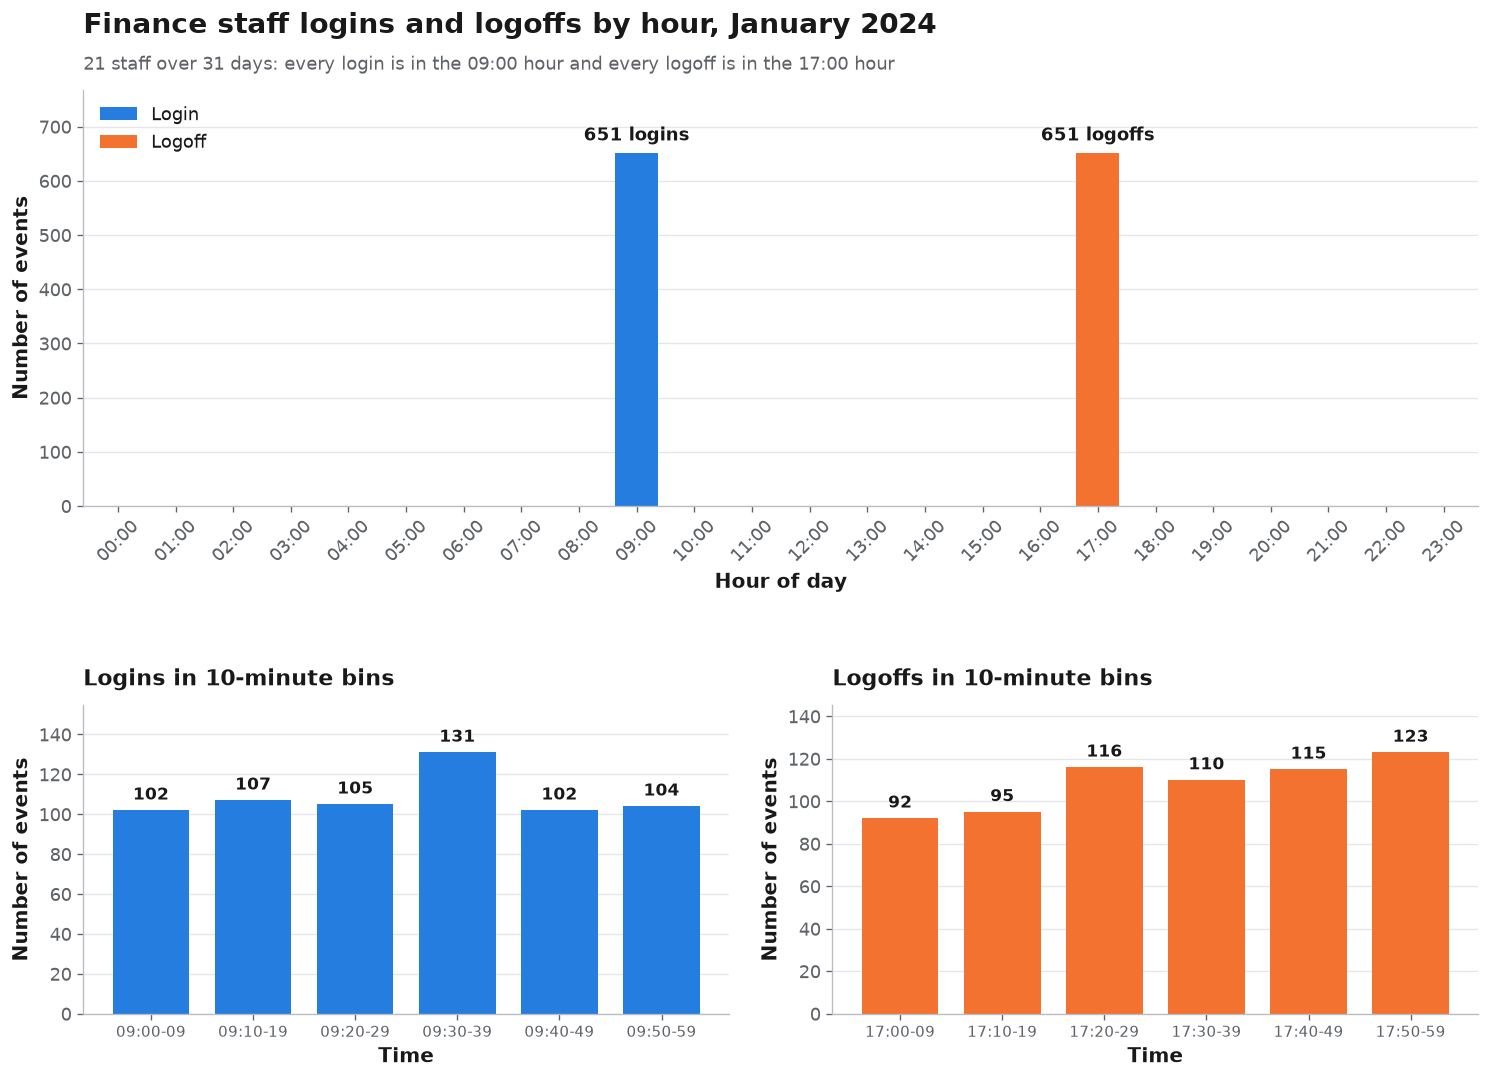

Most common login time: 09:00 (651 logins)
Most common logoff time: 17:00 (651 logoffs)


In [11]:
import numpy as np
from matplotlib.ticker import FuncFormatter

# ---------- Shared chart style ----------
# rcParams are matplotlib's default settings. Setting them once here means every later chart matches,
# so this cell must be run before the other questions.
INK, MUTED, GRID = '#191919', '#5f6368', '#e3e6ea'
plt.rcParams.update({
    'figure.dpi': 120, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 11, 'text.color': INK,
    'axes.titlesize': 17, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 12, 'axes.labelweight': 'bold', 'axes.labelcolor': INK,
    'axes.edgecolor': '#b8bdc4', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False
})

def add_titles(ax, title, subtitle):
    """Add a bold title with a lighter explanatory line beneath it."""
    ax.set_title(title, pad=34)
    # xycoords='axes fraction' means (0, 1) is the top-left corner of the plot, whatever the data range.
    ax.annotate(subtitle, xy=(0, 1), xycoords='axes fraction', xytext=(0, 12),
                textcoords='offset points', color=MUTED, fontsize=11)

LOGIN_COLOR, LOGOFF_COLOR = '#257de0', '#f47230'

# ---------- Step 1: filter ----------
# Each line is a True/False test on every row. & means AND, so a row must pass all three tests.
# .copy() makes a separate table, so adding columns does not alter login_data.
finance_users = user_set['Finance']
finance_january = login_data[
    login_data['user'].isin(finance_users) &
    (login_data['datetime'].dt.year == 2024) &
    (login_data['datetime'].dt.month == 1)
].copy()

# ---------- Step 2: count events per hour ----------
# .dt.hour extracts the hour (0-23). groupby().size() counts the rows for each hour/action pair.
# unstack() turns the actions into columns, and reindex() adds the hours that have no events as 0.
finance_january['hour'] = finance_january['datetime'].dt.hour
hourly_counts = finance_january.groupby(['hour', 'action']).size().unstack(fill_value=0)
hourly_counts = hourly_counts.reindex(index=range(24), columns=['login', 'logoff'], fill_value=0)

# idxmax() returns the index label (the hour) of the largest value, not the value itself.
login_hour = hourly_counts['login'].idxmax()
logoff_hour = hourly_counts['logoff'].idxmax()

# ---------- Step 3: plot ----------
# GridSpec layout: one wide hourly chart on top, two detailed charts underneath.
fig = plt.figure(figsize=(15, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.35, 1], hspace=0.55, wspace=0.16)
ax = fig.add_subplot(grid[0, :])
for action, color in [('login', LOGIN_COLOR), ('logoff', LOGOFF_COLOR)]:
    bars = ax.bar(hourly_counts.index, hourly_counts[action], width=0.75, color=color, label=action.capitalize())
    # Label the bars that are not zero with their exact count.
    ax.bar_label(bars, labels=[f'{v:,} {action}s' if v else '' for v in hourly_counts[action]],
                 padding=5, fontsize=11, fontweight='bold')
ax.set_xticks(range(24), [f'{h:02d}:00' for h in range(24)], rotation=45)
ax.set_xlim(-0.6, 23.6)
ax.set_ylim(0, hourly_counts.to_numpy().max() * 1.18)
ax.grid(axis='x', visible=False)
add_titles(ax, 'Finance staff logins and logoffs by hour, January 2024',
           f'{len(finance_users)} staff over {finance_january["datetime"].dt.date.nunique()} days: '
           f'every login is in the {login_hour:02d}:00 hour and every logoff is in the {logoff_hour:02d}:00 hour')
ax.set_xlabel('Hour of day')
ax.set_ylabel('Number of events')
ax.legend(loc='upper left')

# The hourly bars hide what happens inside each hour, so split the two busy hours into 10-minute bins.
for column, (action, hour, color) in enumerate([('login', login_hour, LOGIN_COLOR),
                                                 ('logoff', logoff_hour, LOGOFF_COLOR)]):
    detail = fig.add_subplot(grid[1, column])
    minutes = finance_january.loc[finance_january['action'] == action, 'datetime'].dt.minute
    # // is whole-number division: 37 // 10 * 10 = 30, so minute 37 falls into the 30-39 bin.
    bins = (minutes // 10 * 10).value_counts().reindex(range(0, 60, 10), fill_value=0)
    bars = detail.bar(range(6), bins.values, width=0.75, color=color)
    detail.bar_label(bars, padding=4, fontsize=10, fontweight='bold')
    detail.set_xticks(range(6), [f'{hour:02d}:{m:02d}-{m + 9:02d}' for m in bins.index], fontsize=9)
    detail.set_ylim(0, bins.max() * 1.18)
    detail.grid(axis='x', visible=False)
    detail.set_title(f'{action.capitalize()}s in 10-minute bins', fontsize=13, pad=12)
    detail.set_xlabel('Time')
    detail.set_ylabel('Number of events')
plt.show()

# f-strings insert values into text; :02d pads the hour to two digits, e.g. 9 -> 09.
print(f'Most common login time: {login_hour:02d}:00 ({hourly_counts.loc[login_hour, "login"]} logins)')
print(f'Most common logoff time: {logoff_hour:02d}:00 ({hourly_counts.loc[logoff_hour, "logoff"]} logoffs)')

### Question 2: Plot a multi-line chart that shows the logon and logoff times during the month of January for the user of pc42.

*Hint: Filter the data as you need, and make two calls to plt.plot().*

#### (1 mark)



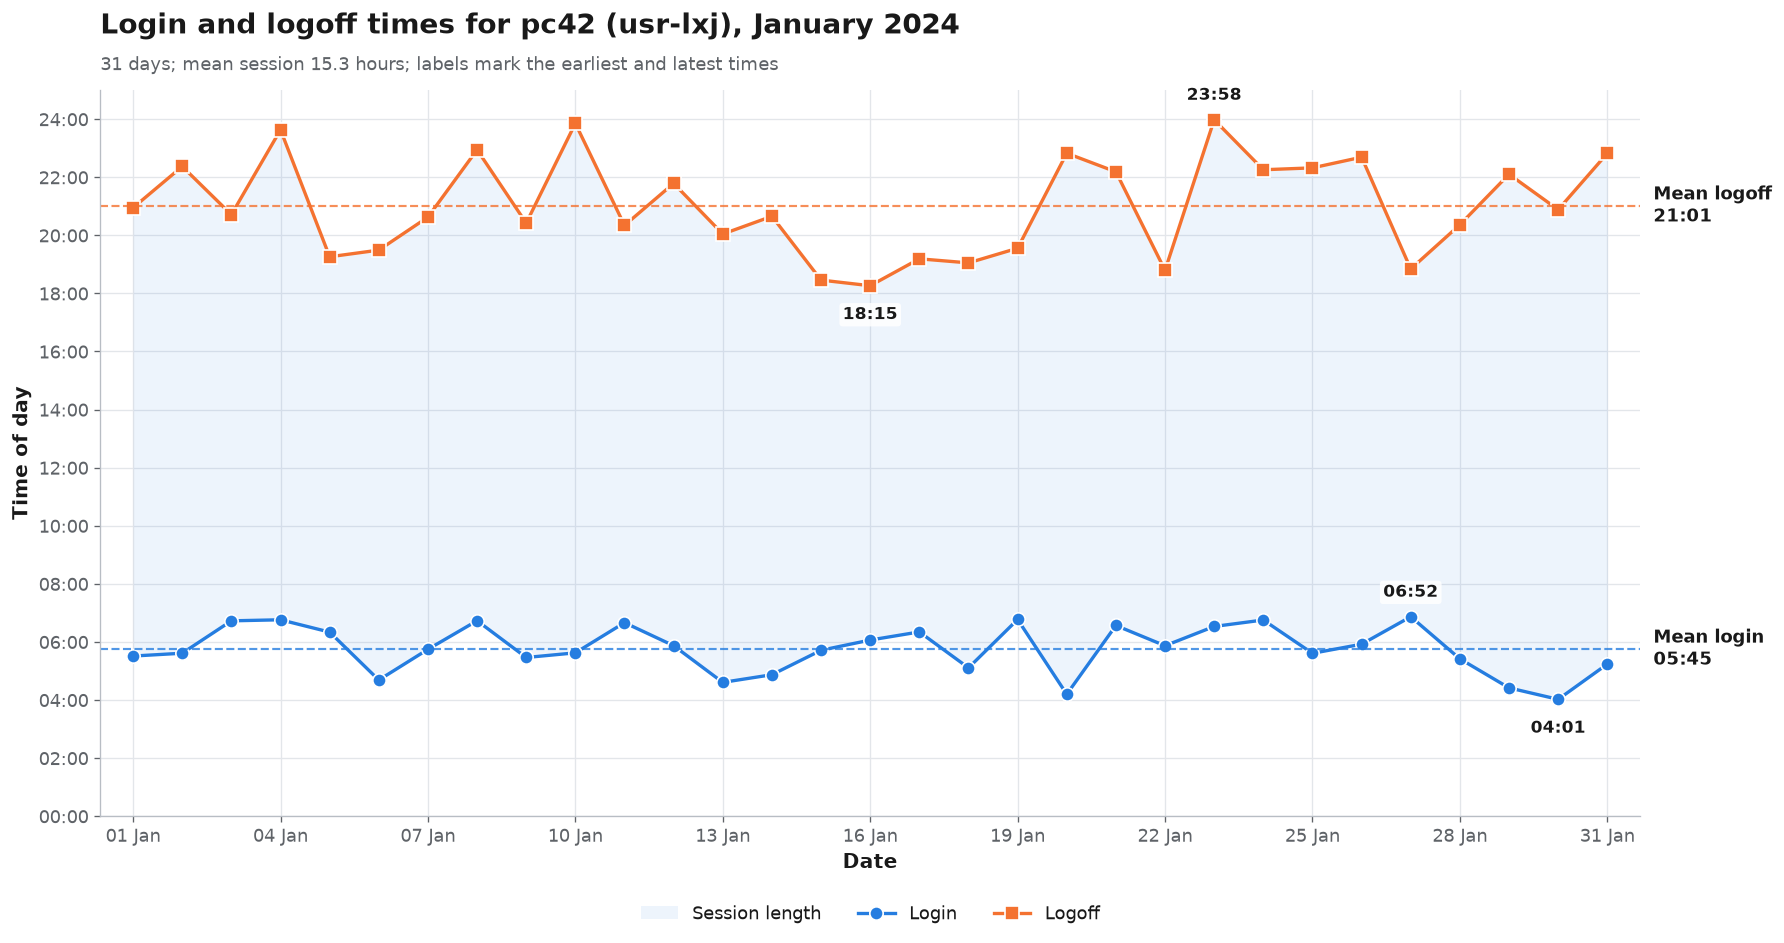

In [12]:
import matplotlib.dates as mdates

# Look up who owns pc42. .loc[rows, column] selects the cell and .iloc[0] takes the first match.
pc42_user = employee_data.loc[employee_data['pc'] == 'pc42', 'user'].iloc[0]
pc42_january = login_data[
    (login_data['pc'] == 'pc42') &
    (login_data['datetime'].dt.year == 2024) &
    (login_data['datetime'].dt.month == 1)
].copy()

# Split each timestamp into a date (x-axis) and a decimal hour (y-axis), e.g. 14:30 -> 14.5.
# normalize() sets the time to midnight, so it keeps only the day.
pc42_january['date'] = pc42_january['datetime'].dt.normalize()
pc42_january['time_hour'] = (
    pc42_january['datetime'].dt.hour +
    pc42_january['datetime'].dt.minute / 60 +
    pc42_january['datetime'].dt.second / 3600
)
# One row per day, with a login column and a logoff column.
daily_times = pc42_january.groupby(['date', 'action'])['time_hour'].mean().unstack()
daily_times = daily_times.reindex(columns=['login', 'logoff'])

def clock(hour, _=None):
    """Convert a decimal hour to clock text, e.g. 14.5 -> 14:30."""
    # int() drops the seconds, so the label matches the log, e.g. 03:53:30 -> 03:53.
    # The tiny extra amount avoids decimal rounding errors.
    total_minutes = int(hour * 60 + 1e-6)
    return f'{total_minutes // 60:02d}:{total_minutes % 60:02d}'

fig, ax = plt.subplots(figsize=(15, 8))
# fill_between shades the time between login and logoff, i.e. the length of the working day.
ax.fill_between(daily_times.index, daily_times['login'], daily_times['logoff'],
                color='#257de0', alpha=0.08, linewidth=0, label='Session length')
for action, color, marker in [('login', LOGIN_COLOR, 'o'), ('logoff', LOGOFF_COLOR, 's')]:
    ax.plot(daily_times.index, daily_times[action], color=color, marker=marker, markersize=8,
            markeredgecolor='white', linewidth=2, label=action.capitalize())
    # The dashed line is this user's average, to show which days are unusually early or late.
    mean_time = daily_times[action].mean()
    ax.axhline(mean_time, color=color, linestyle='--', linewidth=1.3, alpha=0.8)
    ax.annotate(f'Mean {action}\n{clock(mean_time)}', xy=(1, mean_time), xycoords=('axes fraction', 'data'),
                xytext=(8, 0), textcoords='offset points', va='center', fontsize=11, fontweight='bold')
    # Label the earliest and latest time of each line.
    for day, offset in [(daily_times[action].idxmin(), -20), (daily_times[action].idxmax(), 12)]:
        ax.annotate(clock(daily_times.loc[day, action]), (day, daily_times.loc[day, action]), xytext=(0, offset),
                    textcoords='offset points', ha='center', fontsize=10, fontweight='bold', zorder=5,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))

session_hours = (daily_times['logoff'] - daily_times['login']).mean()
add_titles(ax, f'Login and logoff times for pc42 ({pc42_user}), January 2024',
           f'{len(daily_times)} days; mean session {session_hours:.1f} hours; labels mark the earliest and latest times')
ax.set_xlabel('Date')
ax.set_ylabel('Time of day')
ax.set_ylim(0, 25)
ax.set_xlim(pd.Timestamp('2023-12-31 08:00'), pd.Timestamp('2024-01-31 16:00'))
ax.set_yticks(range(0, 25, 2))
# The formatters turn numbers into readable axis text: clock times and "01 Jan" style dates.
ax.yaxis.set_major_formatter(FuncFormatter(clock))
ax.set_xticks(pd.date_range('2024-01-01', '2024-01-31', freq='3D'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.show()

### Question 3: Use a node-link graph to show all emails sent by Security staff on January 5th 2024. Your node link graph may show only those users who receive emails from the select senders.

*Hint: Filter the data and then refer back to Question 4 from Part 1 to format the data correctly*

#### (1 mark)

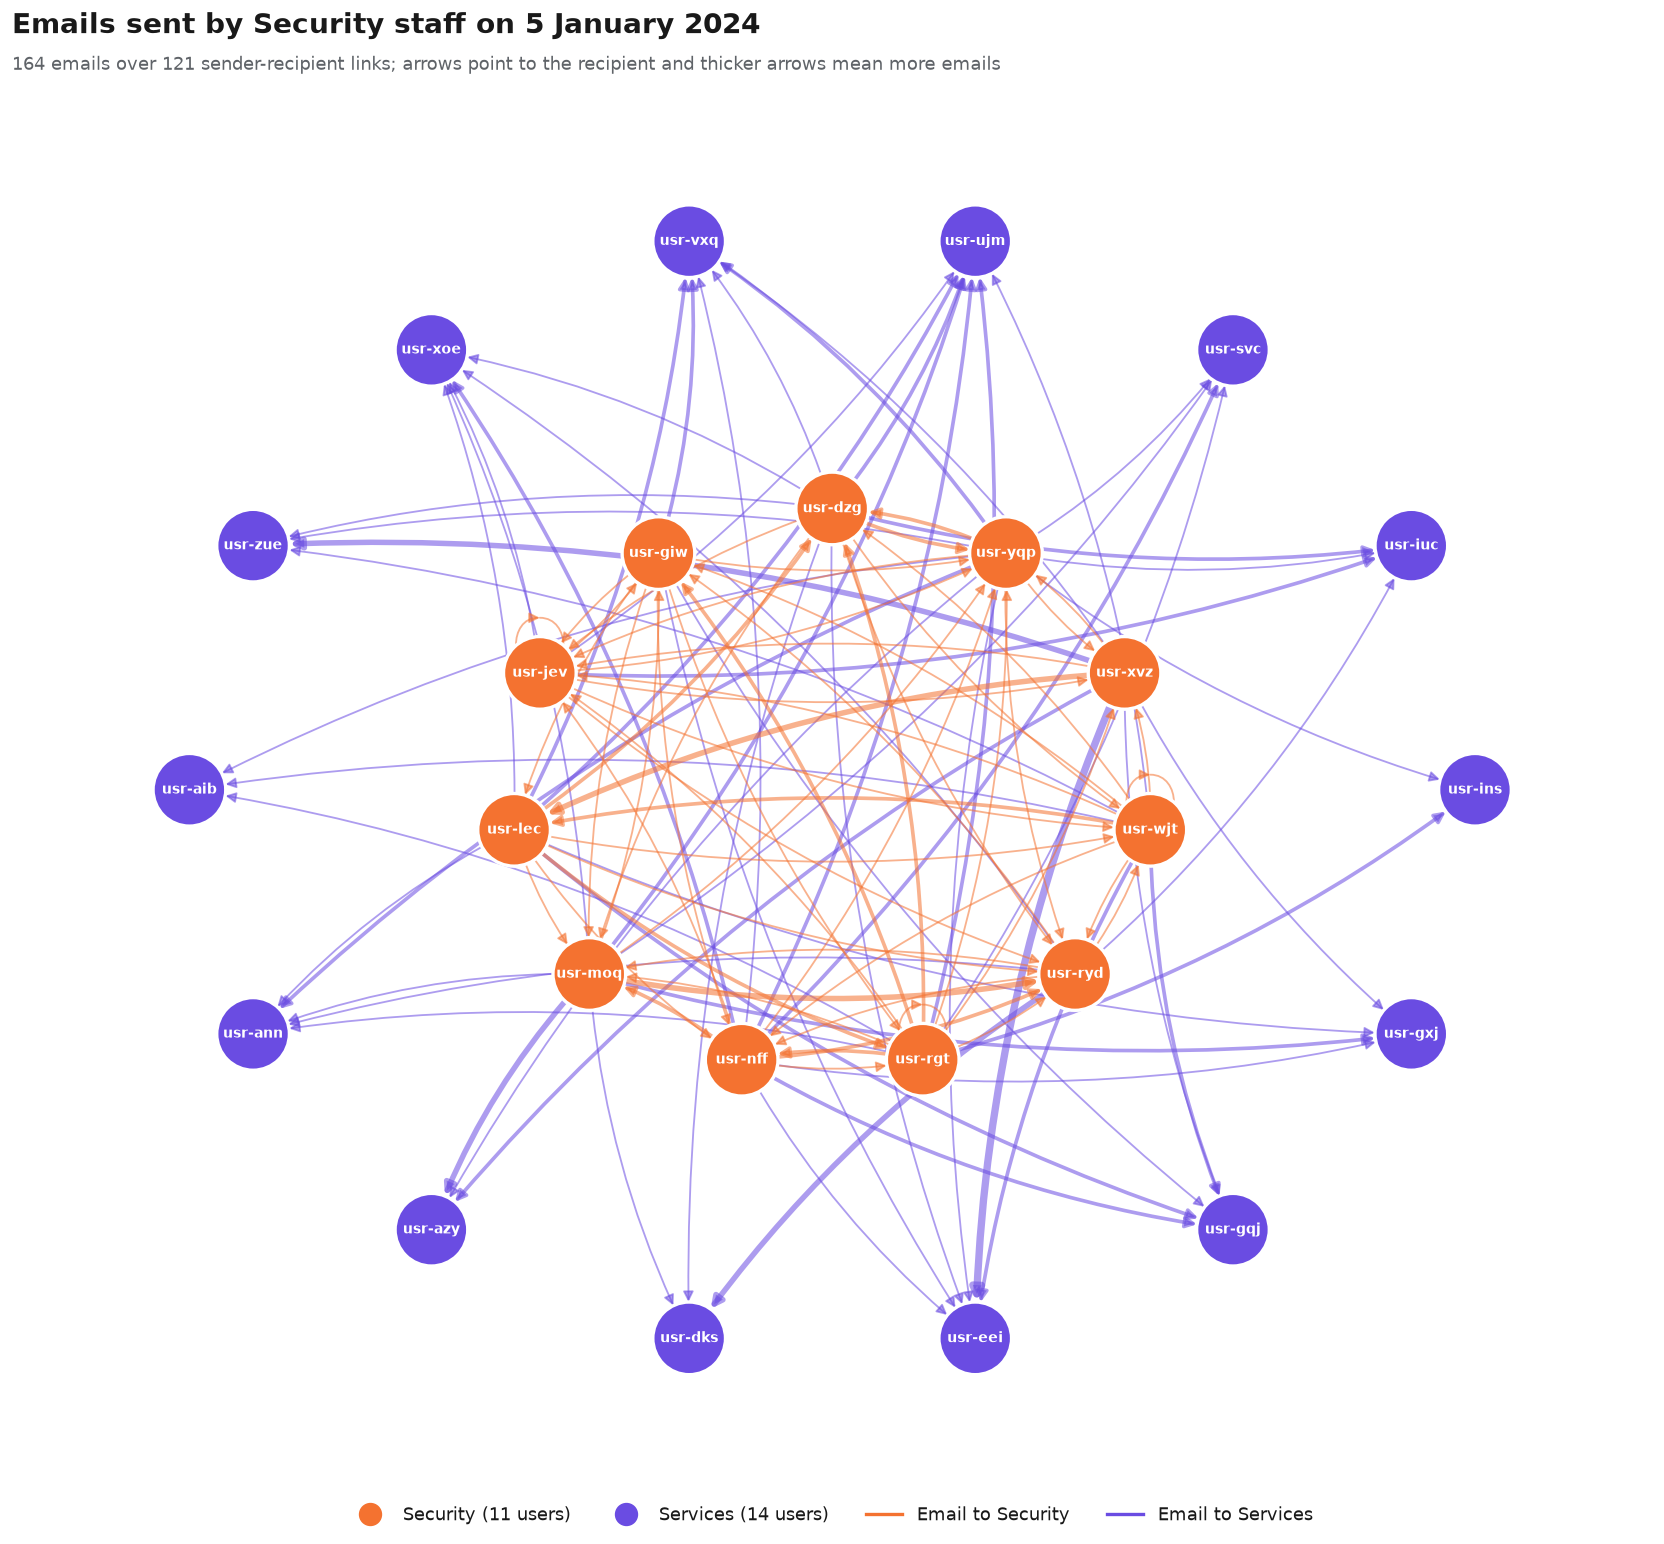

Emails: 164 | Distinct sender-recipient links: 121


In [13]:
import networkx as nx
from matplotlib.lines import Line2D

# ---------- Step 1: keep Security staff's emails on 5 January 2024 ----------
# The supplied logs cover 2024, so use the matching 5 January 2024 records.
security_emails = user_set_emails['Security']
jan5_security = email_data[
    (email_data['datetime'].dt.date == pd.Timestamp('2024-01-05').date()) &
    (email_data['sender'].isin(security_emails))
].copy()

# ---------- Step 2: build an edge list ----------
# Count the emails for each sender/recipient pair. Each pair becomes one edge (arrow).
email_edges = jan5_security.groupby(['sender', 'recipient']).size().reset_index(name='count')
# 'usr-abc@company.com'.split('@') gives ['usr-abc', 'company.com']; .str[0] keeps the username.
email_edges['sender_user'] = email_edges['sender'].str.split('@').str[0]
email_edges['recipient_user'] = email_edges['recipient'].str.split('@').str[0]

# ---------- Step 3: build the graph ----------
# DiGraph = directed graph, so A -> B (A emailed B) is different from B -> A.
G3 = nx.DiGraph()
# iterrows() loops through the table one row at a time; row['count'] reads that row's count column.
for _, row in email_edges.iterrows():
    G3.add_edge(row['sender_user'], row['recipient_user'], weight=row['count'])

# Give each role one fixed colour, reused in Question 4.
role_colors = {
    'Director': '#ec4647', 'Finance': '#00b894', 'HR': '#008a17', 'Legal': '#f2a600',
    'Security': '#f47230', 'Services': '#6a4ce2', 'Technical': '#257de0'
}
# A Series indexed by username works like a lookup table: user_role['usr-abc'] -> role.
user_role = employee_data.set_index('user')['role']
security_users = set(user_set['Security'])

# ---------- Step 4: choose positions ----------
# Security (the senders) form the inner ring and other recipients form the outer ring.
inner_users = sorted(user for user in G3 if user in security_users)
outer_users = sorted(user for user in G3 if user not in security_users)
pos = nx.shell_layout(G3, nlist=[inner_users, outer_users])

# ---------- Step 5: draw ----------
def draw_email_edges(graph, positions, axis, node_size):
    """Draw arrows coloured by the recipient's role; thicker arrows mean more emails."""
    for internal in [False, True]:
        # A list comprehension builds a list by looping and filtering in one line.
        edges = [(u, v) for u, v in graph.edges if (v in security_users) == internal]
        nx.draw_networkx_edges(
            graph, positions, ax=axis, edgelist=edges, node_size=node_size,
            width=[1.1 * graph[u][v]['weight'] for u, v in edges],
            edge_color=role_colors['Security'] if internal else role_colors['Services'],
            alpha=0.55, arrowstyle='-|>', arrowsize=13, connectionstyle='arc3,rad=0.1')

fig, ax = plt.subplots(figsize=(14, 13))
draw_email_edges(G3, pos, ax, 1900)
nx.draw_networkx_nodes(G3, pos, ax=ax, node_size=1900, edgecolors='white', linewidths=2,
                       node_color=[role_colors[user_role[user]] for user in G3])
nx.draw_networkx_labels(G3, pos, ax=ax, font_size=8.5, font_weight='bold', font_color='white')

roles_shown = sorted({user_role[user] for user in G3})
handles = [Line2D([], [], marker='o', linestyle='', markersize=13, color=role_colors[role],
                  label=f'{role} ({sum(user_role[u] == role for u in G3)} users)') for role in roles_shown]
handles += [Line2D([], [], color=role_colors['Security'], linewidth=2, label='Email to Security'),
            Line2D([], [], color=role_colors['Services'], linewidth=2, label='Email to Services')]
ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4)
add_titles(ax, 'Emails sent by Security staff on 5 January 2024',
           f'{len(jan5_security)} emails over {len(email_edges)} sender-recipient links; '
           'arrows point to the recipient and thicker arrows mean more emails')
ax.margins(0.08)
ax.axis('off')
plt.tight_layout()
plt.show()
print('Emails:', len(jan5_security), '| Distinct sender-recipient links:', len(email_edges))

### (Advanced) Question 4: Extend the above, now showing a node for every possible user. The edge connections should be as above, for emails sent by Security staff on 5th January 2024. You should use a shell layout for your network plot.

*Hint: Think about how to include all users as nodes. You may even include a dummy node and remove this in your processing depending on how you form your edgelist - https://networkx.org/documentation/stable/index.html*

#### (3 marks)

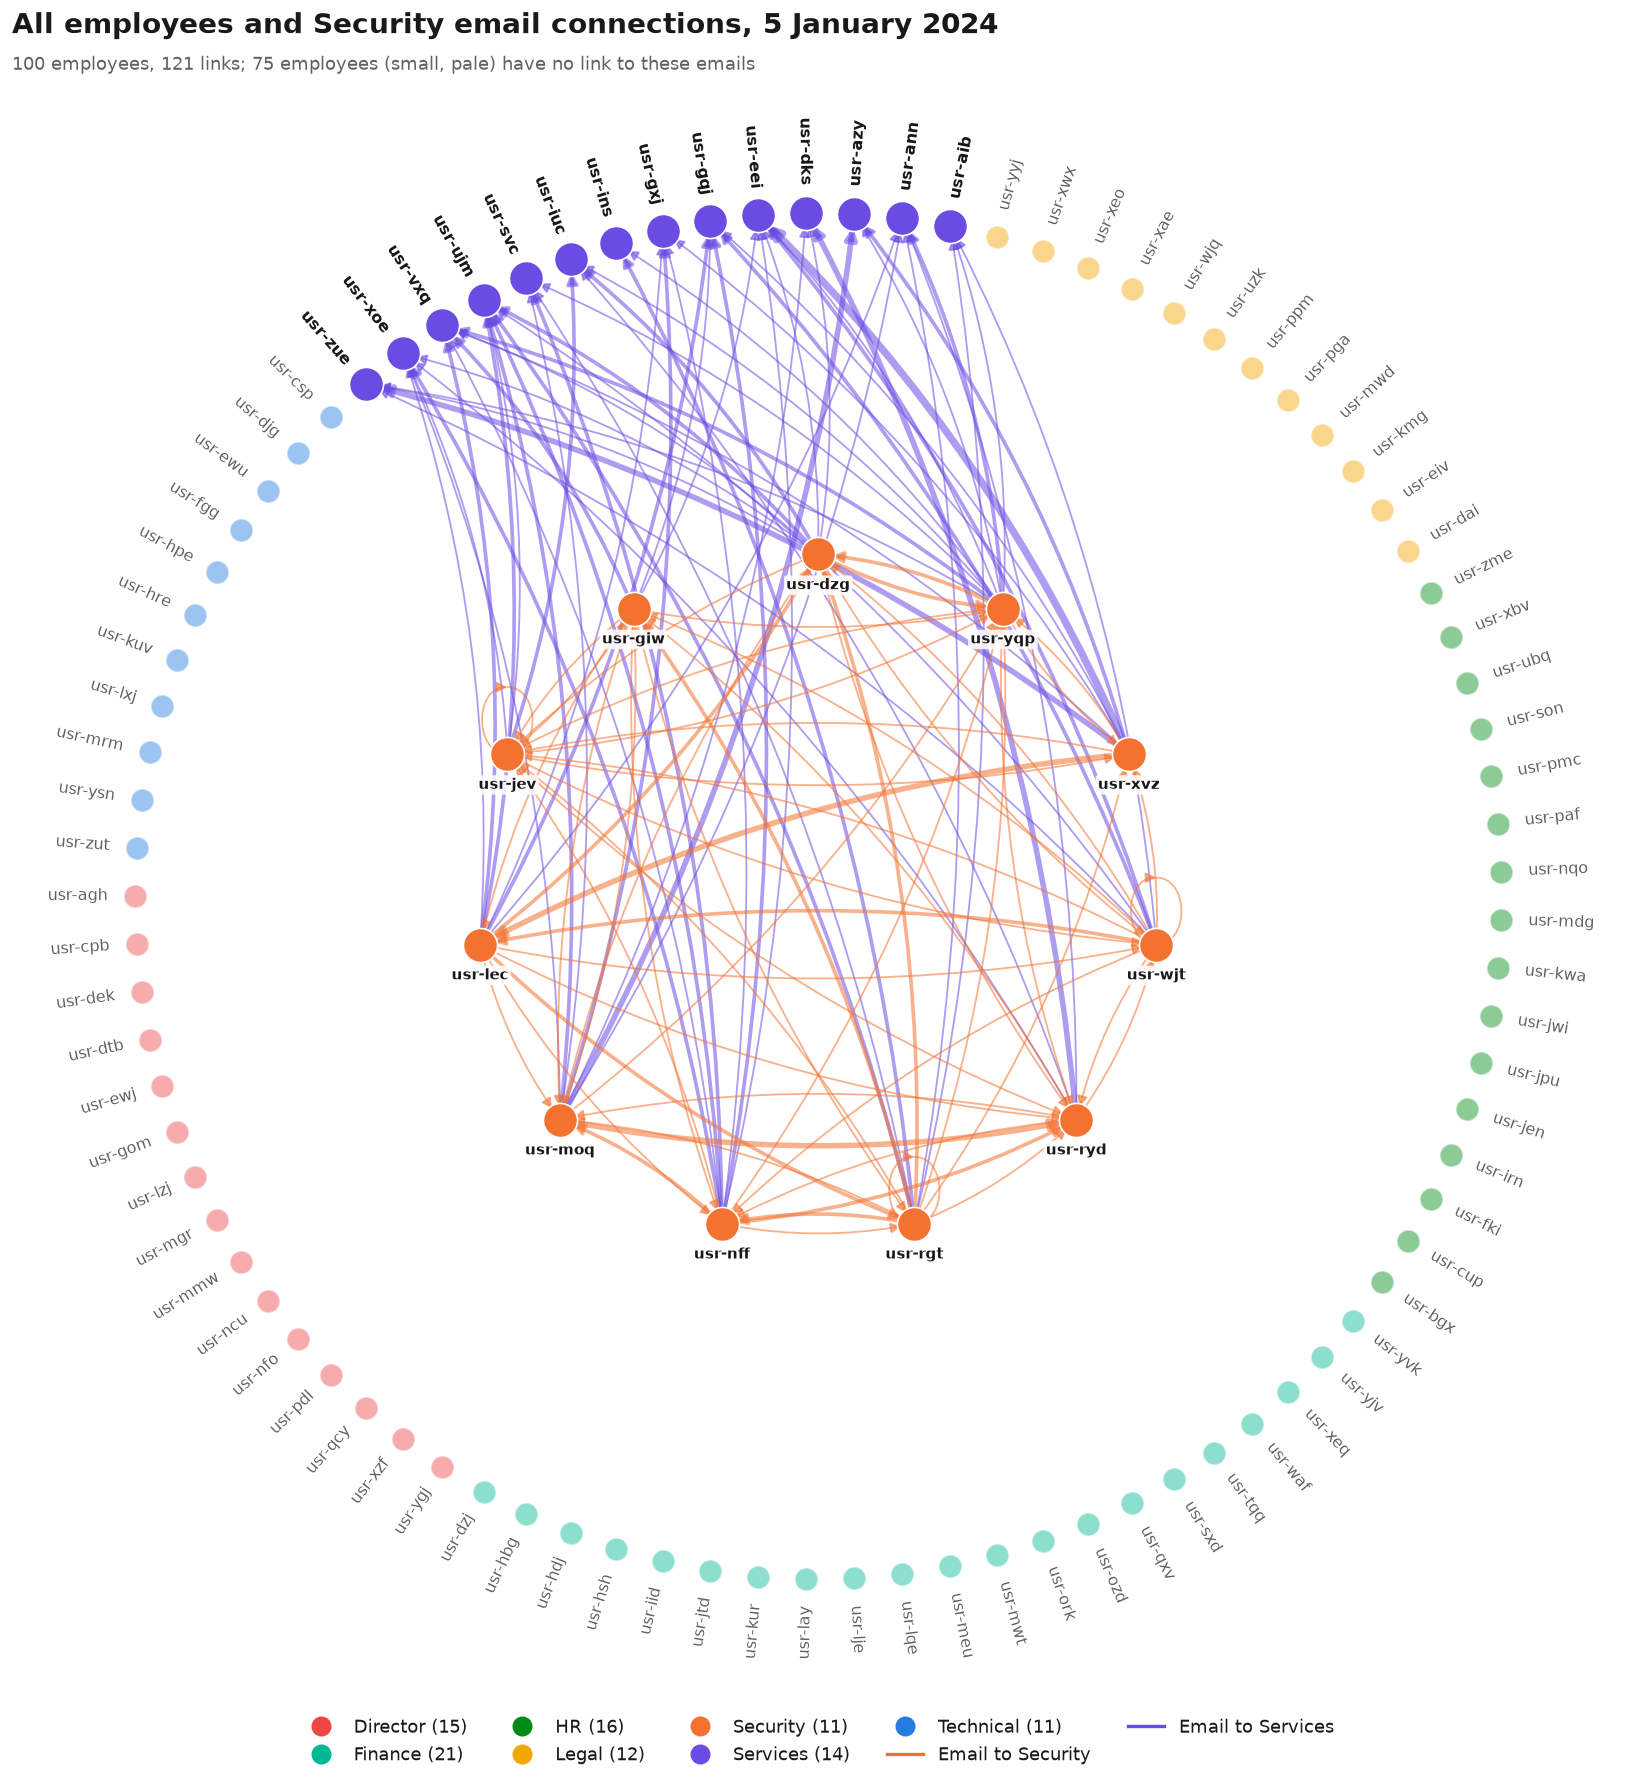

Employee nodes: 100 | Email links: 121


In [14]:
# Add every employee first, so people with no emails still appear as nodes.
# No dummy node is needed, because add_nodes_from() can create nodes without any edges.
G4 = nx.DiGraph()
all_users = employee_data['user'].tolist()
G4.add_nodes_from(all_users)
# Reuse the Question 3 edge list.
for _, row in email_edges.iterrows():
    G4.add_edge(row['sender_user'], row['recipient_user'], weight=row['count'])

# Shell layout places each list in nlist on its own ring. Security is the inner ring.
# The outer ring is sorted by role and then name, so that each role forms one block.
inner_users = sorted(security_users)
outer_users = sorted(set(all_users) - security_users, key=lambda user: (user_role[user], user))
pos = nx.shell_layout(G4, nlist=[inner_users, outer_users])

fig, ax = plt.subplots(figsize=(15, 15))
draw_email_edges(G4, pos, ax, 260)

# degree counts the links of each node; nodes with none are drawn paler.
connected = {user for user in G4 if G4.degree(user) > 0}
for role, color in role_colors.items():
    for is_connected in [True, False]:
        nodes = [u for u in all_users if user_role[u] == role and (u in connected) == is_connected]
        nx.draw_networkx_nodes(G4, pos, ax=ax, nodelist=nodes, node_color=color,
                               node_size=420 if is_connected else 190, alpha=1 if is_connected else 0.45,
                               edgecolors='white', linewidths=1)

# Rotate the outer labels to point away from the centre, so that all 89 fit without overlapping.
for user in outer_users:
    x, y = pos[user] * 1.04
    angle = np.degrees(np.arctan2(y, x))   # direction of this node from the centre, in degrees
    flip = abs(angle) > 90                 # flip labels on the left so they are not upside down
    ax.text(x, y, user, rotation=angle + 180 if flip else angle, rotation_mode='anchor',
            ha='right' if flip else 'left', va='center', fontsize=9.5,
            fontweight='bold' if user in connected else 'normal',
            color=INK if user in connected else MUTED)
for user in inner_users:
    ax.annotate(user, pos[user], xytext=(0, -14), textcoords='offset points', ha='center', va='top',
                fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))

handles = [Line2D([], [], marker='o', linestyle='', markersize=11, color=color,
                  label=f'{role} ({len(user_set[role])})') for role, color in role_colors.items()]
handles += [Line2D([], [], color=role_colors['Security'], linewidth=2, label='Email to Security'),
            Line2D([], [], color=role_colors['Services'], linewidth=2, label='Email to Services')]
ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=5)
add_titles(ax, 'All employees and Security email connections, 5 January 2024',
           f'{G4.number_of_nodes()} employees, {G4.number_of_edges()} links; '
           f'{len(all_users) - len(connected)} employees (small, pale) have no link to these emails')
ax.set(xlim=(-1.18, 1.18), ylim=(-1.18, 1.18), aspect='equal')
ax.axis('off')
plt.tight_layout()
plt.show()
print('Employee nodes:', G4.number_of_nodes(), '| Email links:', G4.number_of_edges())

### Question 5: Show a comparison between the files accessed by HR staff, Services staff, and Security staff, during January. You will need to think of a suitable way to convey this information within a single plot so that comparison of activity can be made easily.

*Hint: Think which plot enables you to make comparisons between two attributes, and then think what the attributes would need to be for mapping three job roles against the possible set of files accessed.*

#### (4 marks)

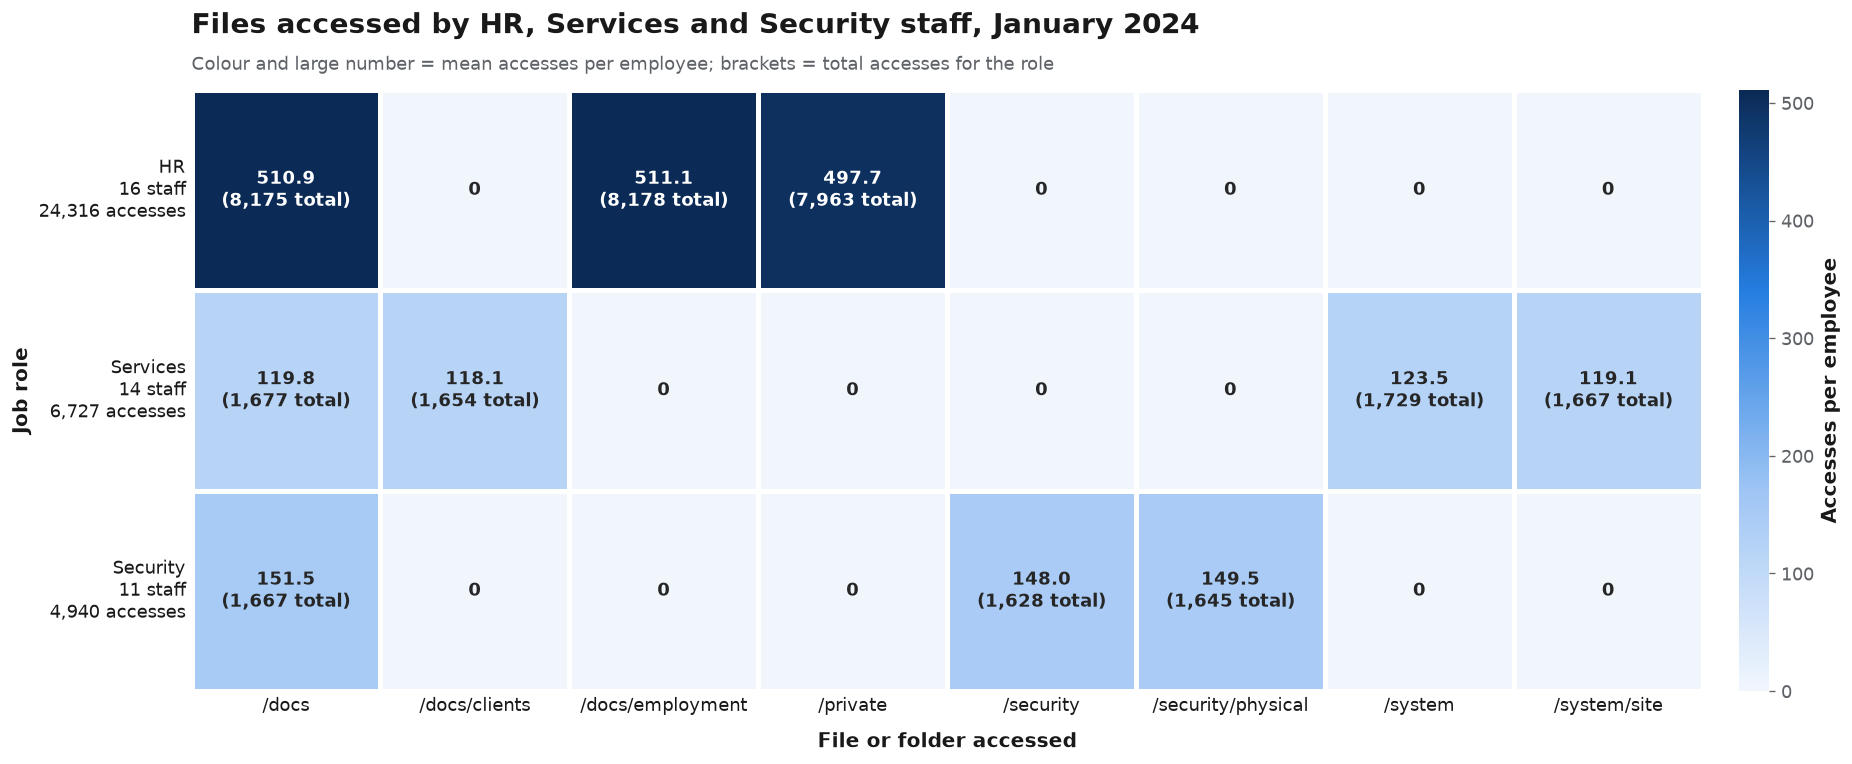

January file accesses per employee, by role:
          count    sum    mean  median
role                                  
HR           16  24316  1519.8  1524.0
Services     14   6727   480.5   481.0
Security     11   4940   449.1   448.0


In [15]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

roles_to_compare = ['HR', 'Services', 'Security']

# Filter to January, then add each row's role by looking its username up in user_role (from Question 3).
january_files = file_data[
    (file_data['datetime'].dt.year == 2024) &
    (file_data['datetime'].dt.month == 1)
].copy()
january_files['role'] = january_files['user'].map(user_role)

# A heatmap compares two attributes at once: role (rows) against file (columns).
# crosstab() counts how often each role/file pair occurs. Keep only the files these roles used.
file_counts = pd.crosstab(january_files['role'], january_files['filename']).loc[roles_to_compare]
file_counts = file_counts.loc[:, file_counts.sum() > 0]

# The roles have different numbers of staff, so colour by the average per employee for a fair comparison.
# div(..., axis=0) divides each row by that role's staff count.
staff = employee_data['role'].value_counts()[roles_to_compare]
per_employee = file_counts.div(staff, axis=0)

# Text for each cell: the average (used for colour), with the total count beneath it.
labels = np.array([[f'{per_employee.loc[r, f]:.1f}\n({file_counts.loc[r, f]:,} total)' if file_counts.loc[r, f] else '0'
                    for f in file_counts.columns] for r in roles_to_compare])

blues = LinearSegmentedColormap.from_list('blues', ['#f1f6fd', '#9ec5f4', '#257de0', '#0b2a55'])
fig, ax = plt.subplots(figsize=(17, 6.5))
sns.heatmap(per_employee, ax=ax, cmap=blues, annot=labels, fmt='', linewidths=3, linecolor='white',
            annot_kws={'fontsize': 11, 'fontweight': 'bold'},
            cbar_kws={'label': 'Accesses per employee', 'pad': 0.02})
ax.grid(False)
ax.tick_params(length=0)
# The role labels include the staff count and the total, so the rows can be compared as a whole.
ax.set_yticklabels([f'{r}\n{staff[r]} staff\n{file_counts.loc[r].sum():,} accesses' for r in roles_to_compare],
                   rotation=0, fontsize=11, color=INK)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=11, color=INK)
add_titles(ax, 'Files accessed by HR, Services and Security staff, January 2024',
           'Colour and large number = mean accesses per employee; brackets = total accesses for the role')
ax.set_xlabel('File or folder accessed', labelpad=10)
ax.set_ylabel('Job role')
plt.tight_layout()
plt.show()

# Summary table: agg() calculates several statistics at once, per role.
per_user = january_files[january_files['role'].isin(roles_to_compare)].groupby(['role', 'user']).size()
print('January file accesses per employee, by role:')
print(per_user.groupby('role').agg(['count', 'sum', 'mean', 'median']).reindex(roles_to_compare).round(1))

### Question 6: Carry on your own investigation to find the anomalous activity across all data files provided. Provide clear evidence and justification for your investigative steps.

Marks are awarded for: 
- a clear explanation of the steps you take to complete your investigation (5)
- suitable use of data analysis with clear explanation (6)
- suitable use of visualisation methods with clear annotation (6)
- identifying all of the suspicious events (8)

#### (25 marks)

STEP 1 - Highest role-relative anomaly scores:
   user      role  after_hours_logins  emails_sent  file_accesses  usb_inserts  web_visits  anomaly_score
usr-ncu  Director                73.0         3633           3565          4.0         569           1.95
usr-eei  Services               121.0         2811           2804        529.0         572           1.46
usr-gxj  Services               116.0         2837           2810        551.0         538           1.25
usr-iuc  Services               134.0         2826           2821        530.0         568           1.15
usr-lxj Technical               111.0        16372          17308        988.0       12325           1.04
usr-djg Technical               132.0        17455          16885        981.0       12801           1.03
usr-mrm Technical               116.0        17476          16713       1025.0       12700           1.03
usr-fki        HR                 0.0         9139           8836        546.0        2698           1.03

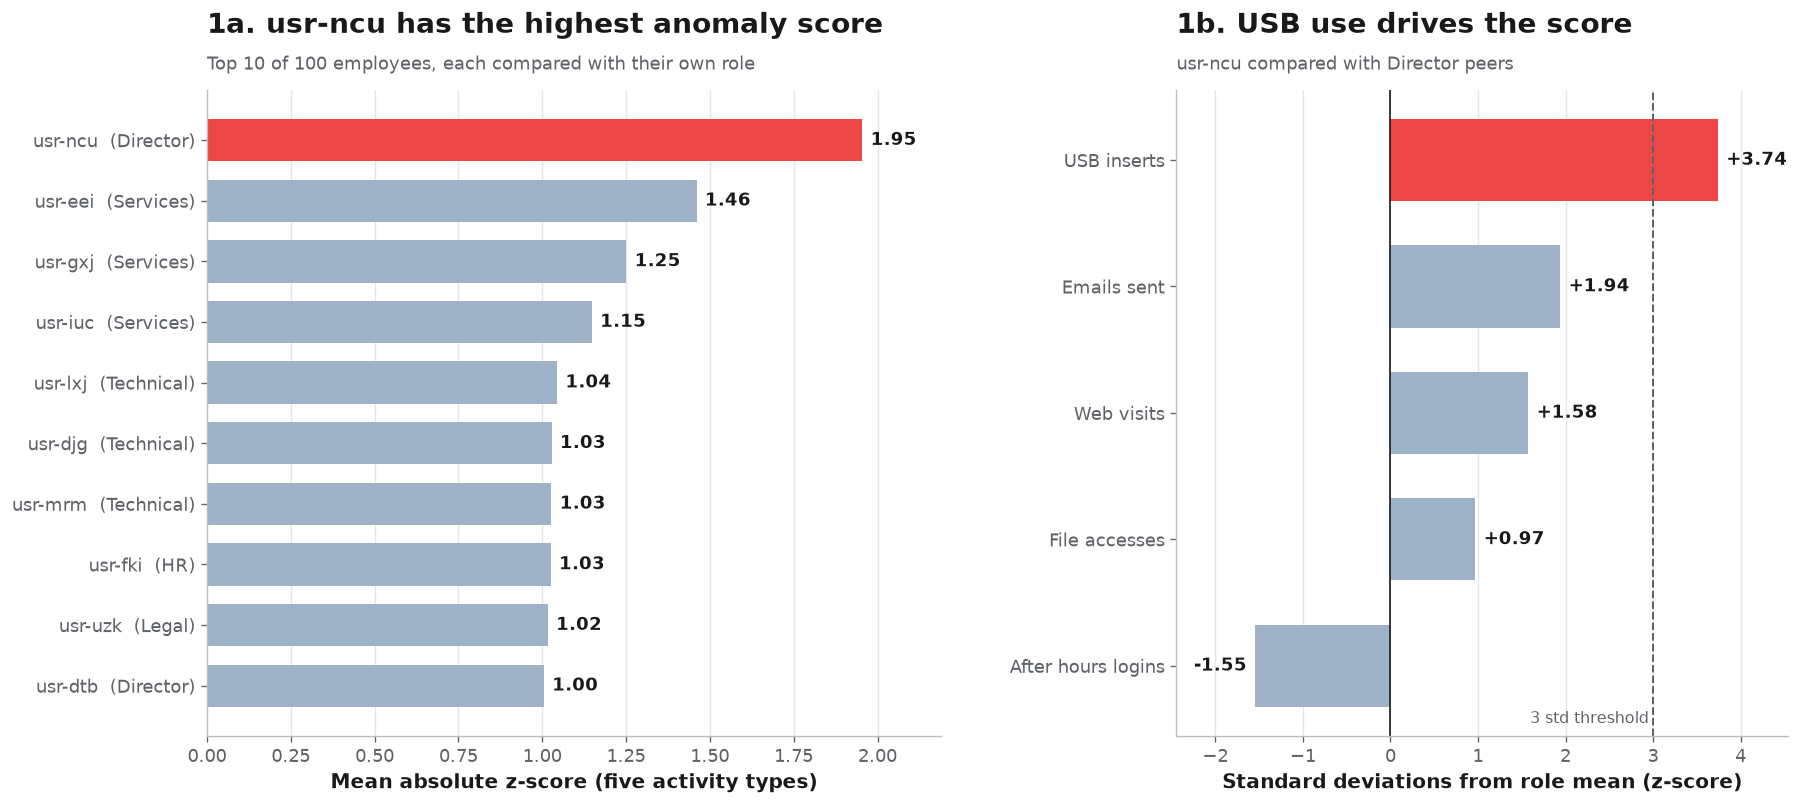


STEP 2 - Days when the suspect exceeded every peer by volume:
  Emails sent: 49 on 18 April 2024, z = 10.3 (highest peer day: 24)
  Files accessed: 25 on 23 April 2024, z = 1.9 (highest peer day: 24)
  Web visits: 12 on 25 April 2024, z = 11.0 (highest peer day: 4)
  USB events: 4 on 23 April 2024, peers = 0 (highest peer day: 0)
  USB events: 4 on 25 April 2024, peers = 0 (highest peer day: 0)


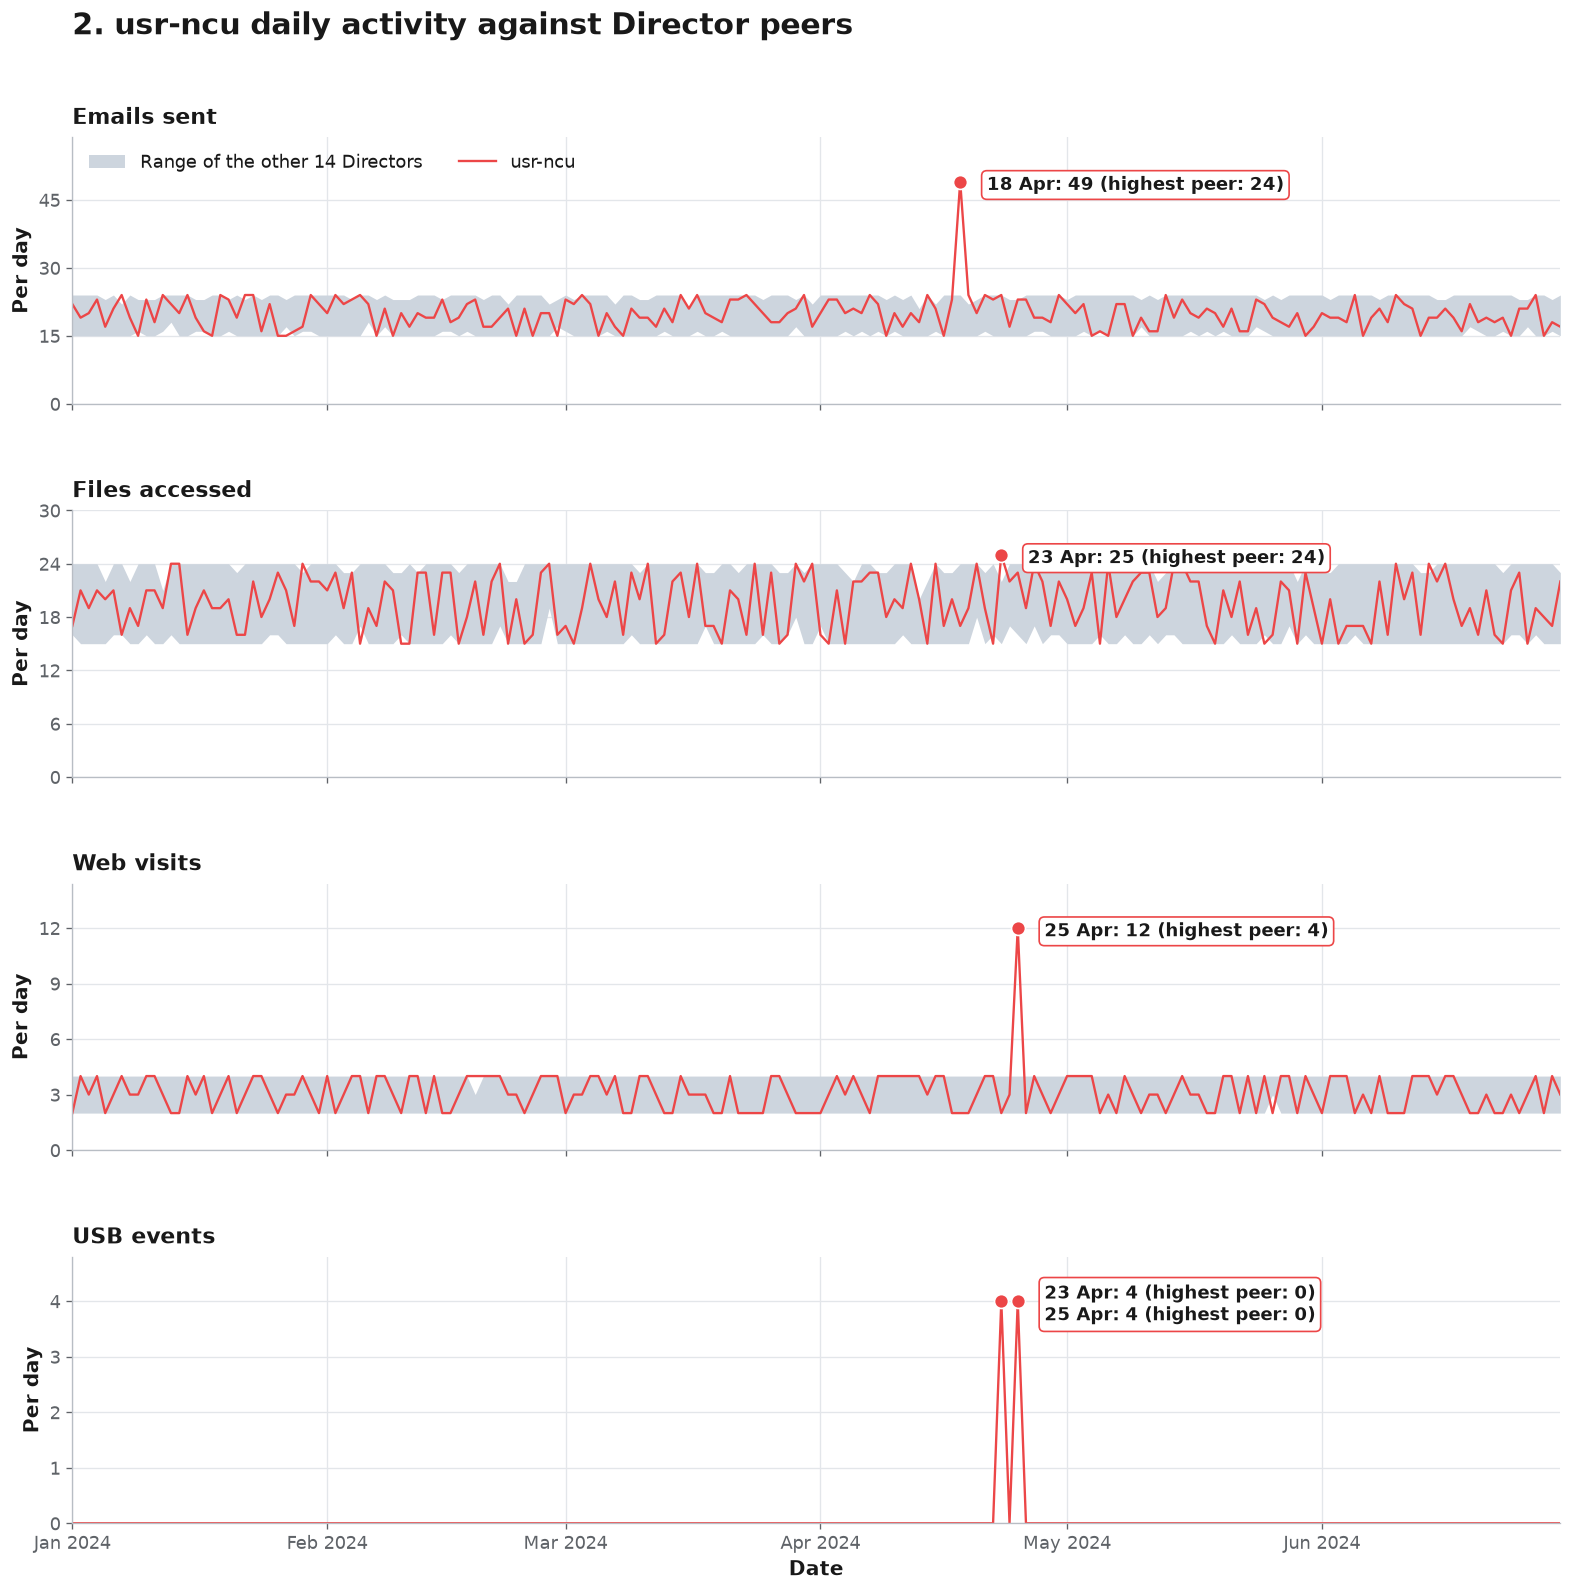


STEP 3 - Files and websites used by only one member of a role (all roles checked):
    role                      item only user  events
Director             /docs/clients   usr-ncu       5
Director http://www.legaleagle.com   usr-ncu       5
Director   http://www.linkedin.com   usr-ncu       5

USB events on another PC: 8, all by usr-ncu on pc99, assigned to usr-rgt (Security)


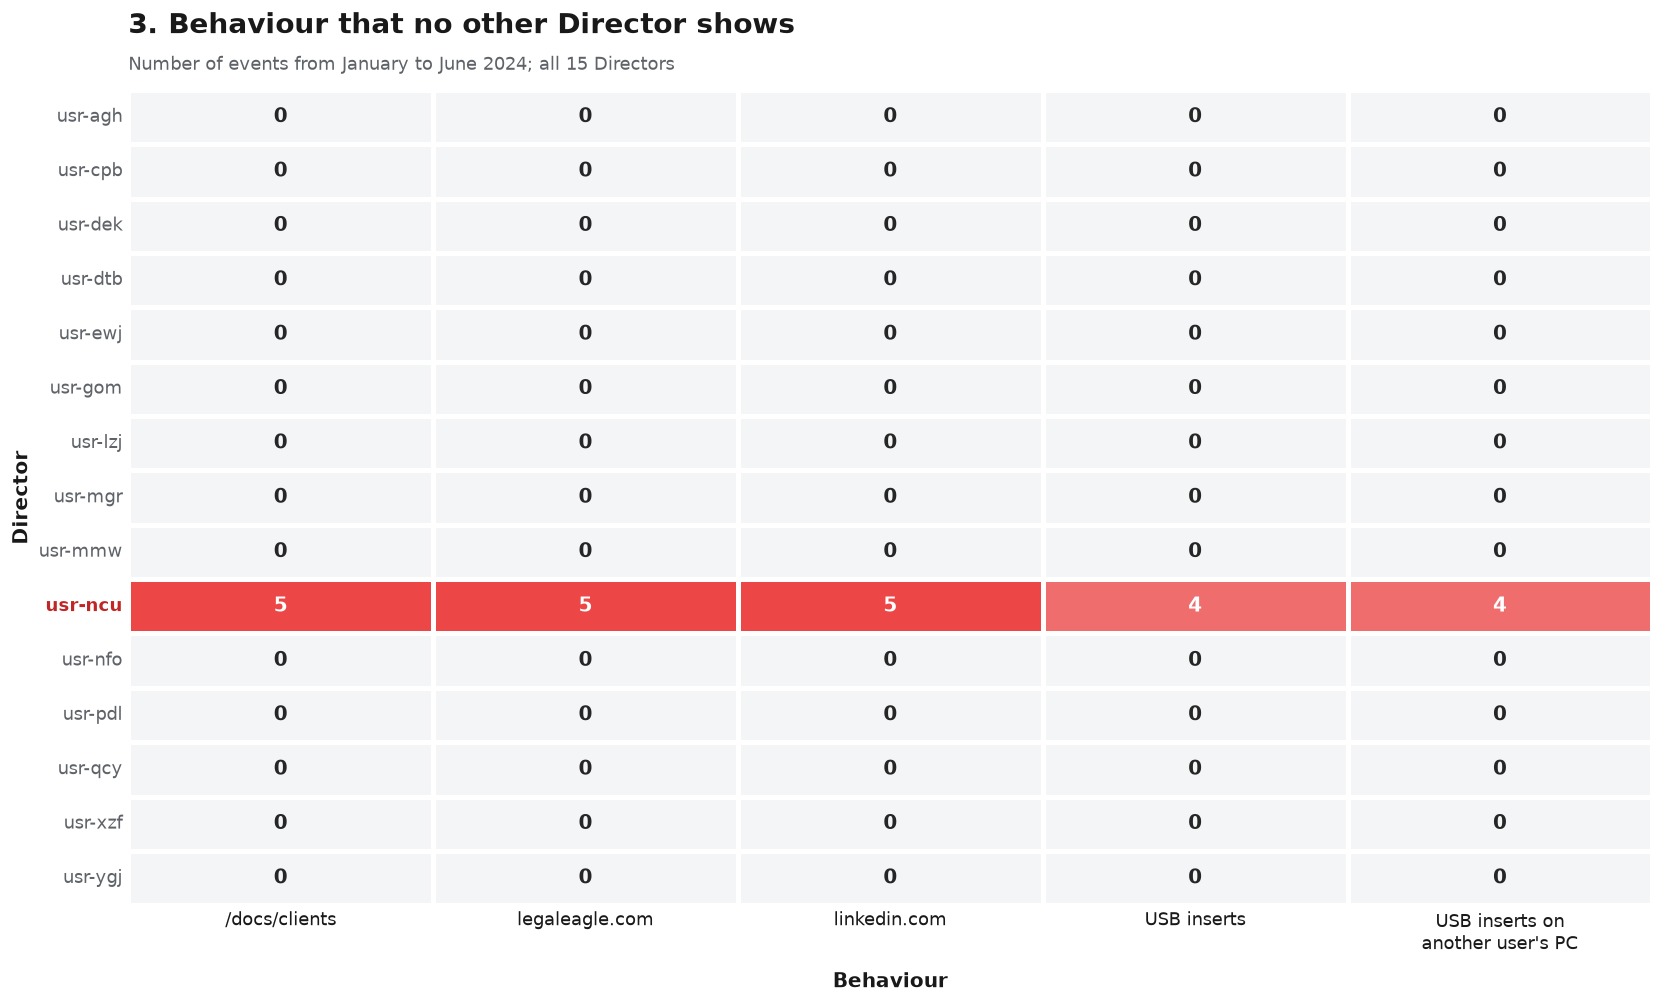


STEP 4 - usr-ncu sent 30 emails to usr-jen (HR) on 18 April 2024; every other Director sender/recipient/day total is at most 5


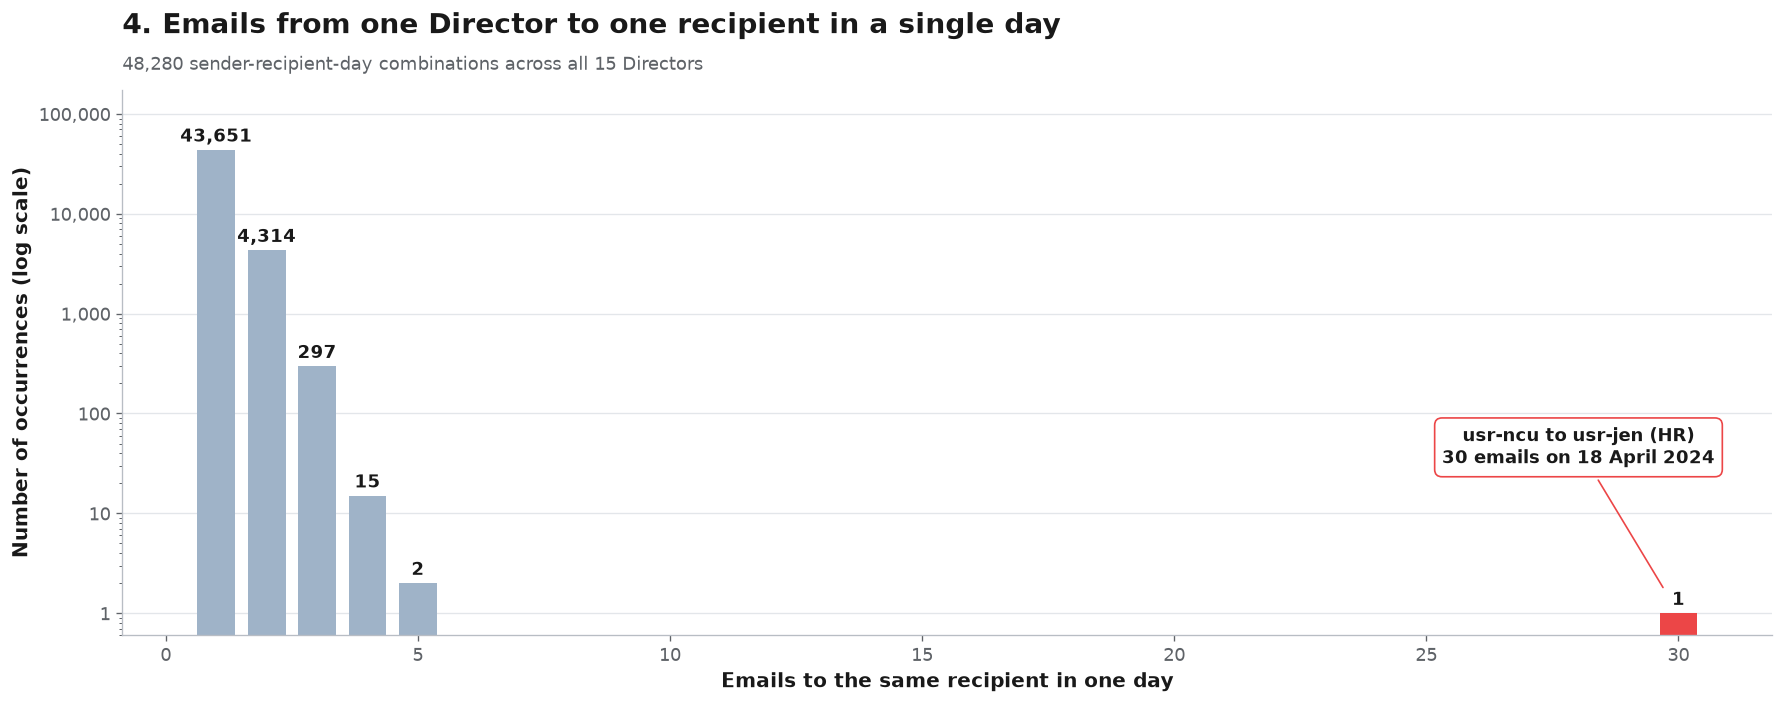

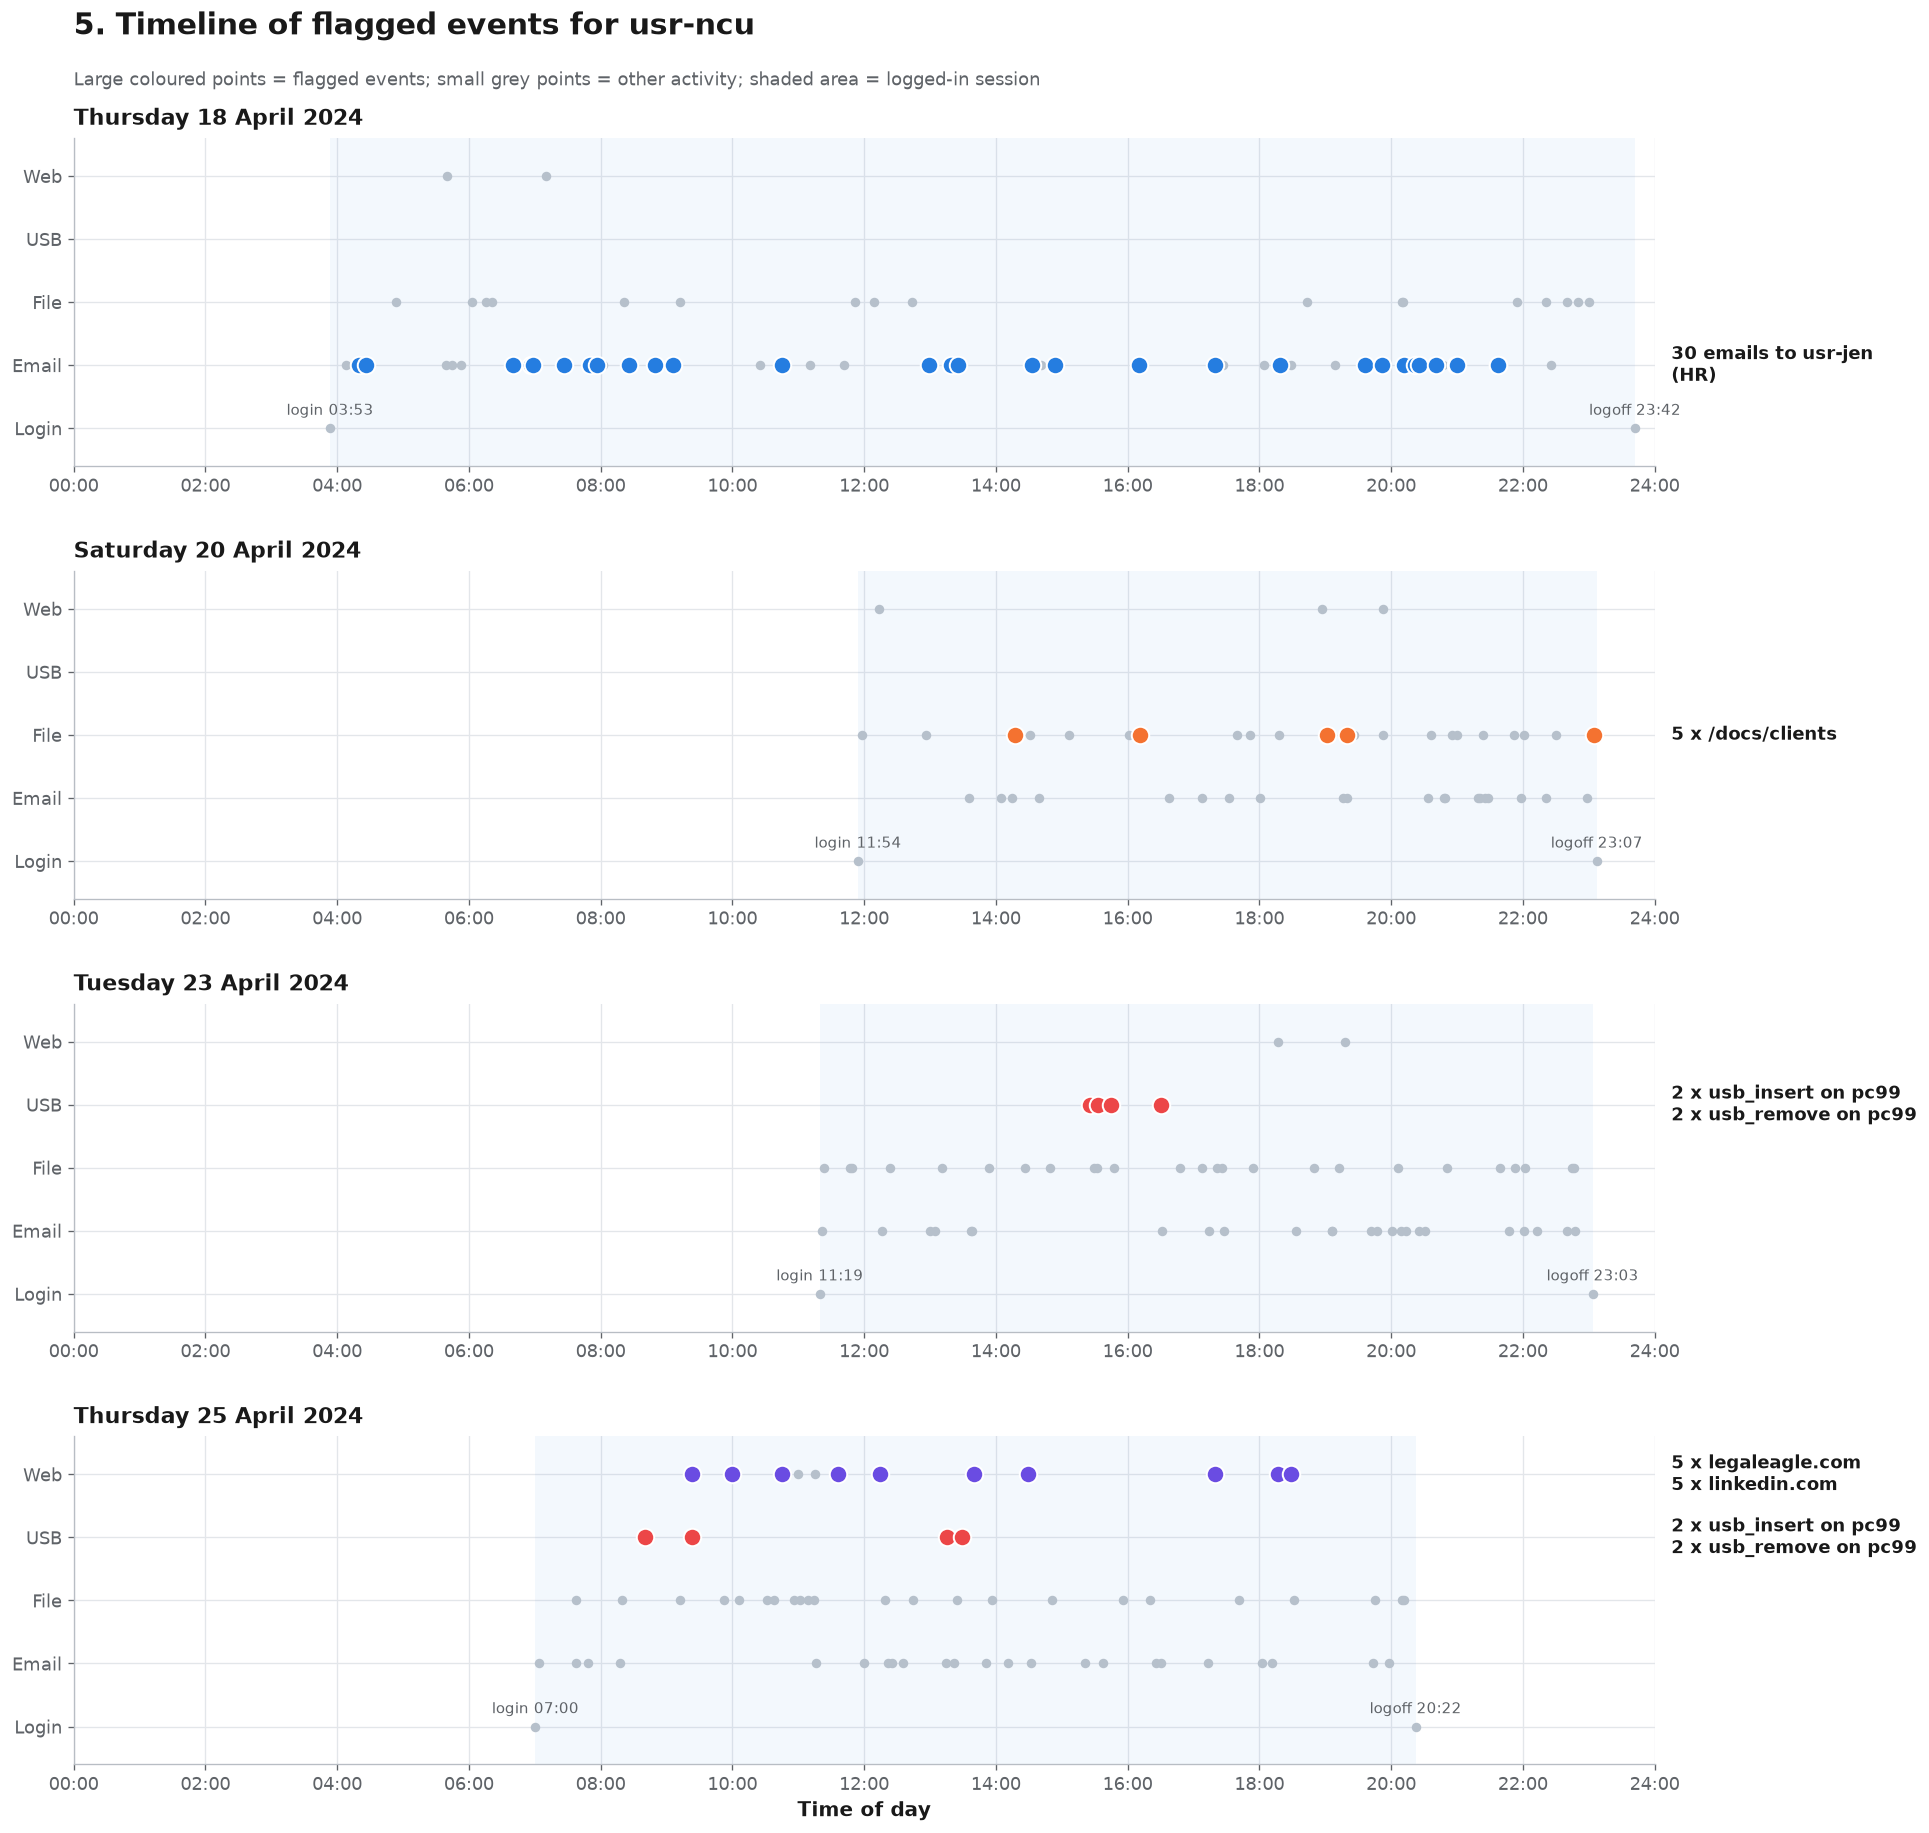

STEP 5 - 53 flagged events for usr-ncu, in time order:
           datetime channel             detail
2024-04-18 04:19:46   email            usr-jen
2024-04-18 04:26:30   email            usr-jen
2024-04-18 06:39:50   email            usr-jen
2024-04-18 06:56:22   email            usr-jen
2024-04-18 06:58:00   email            usr-jen
2024-04-18 07:26:28   email            usr-jen
2024-04-18 07:50:43   email            usr-jen
2024-04-18 07:56:47   email            usr-jen
2024-04-18 08:25:30   email            usr-jen
2024-04-18 08:49:21   email            usr-jen
2024-04-18 09:06:01   email            usr-jen
2024-04-18 10:44:54   email            usr-jen
2024-04-18 12:59:04   email            usr-jen
2024-04-18 13:19:16   email            usr-jen
2024-04-18 13:25:14   email            usr-jen
2024-04-18 14:32:47   email            usr-jen
2024-04-18 14:53:32   email            usr-jen
2024-04-18 16:10:30   email            usr-jen
2024-04-18 17:19:24   email            usr-jen
2024-

In [16]:
# Investigation plan
#   Step 1: find who is most unusual compared with colleagues in the same role.
#   Step 2: find which days that user's activity spiked.
#   Step 3: look for resources that only one person in a role ever used, and for USB use on another person's PC.
#   Step 4: confirm the email spike.
#   Step 5: put all of the flagged events onto one timeline.

# ==================== STEP 1: role-relative anomaly score ====================
SUSPECT_COLOR, NORMAL_COLOR = '#ec4647', '#9fb3c8'
activity = employee_data[['user', 'role']].copy()

# Count logins before 06:00 or from 20:00 for each user. | means OR.
after_hours = login_data[
    (login_data['action'] == 'login') &
    ((login_data['datetime'].dt.hour < 6) | (login_data['datetime'].dt.hour >= 20))
].groupby('user').size()
# map() looks each username up in the counts; users with no rows give NaN, so fillna(0) makes them 0.
activity['after_hours_logins'] = activity['user'].map(after_hours).fillna(0)

email_senders = email_data['sender'].str.split('@').str[0].value_counts()
activity['emails_sent'] = activity['user'].map(email_senders).fillna(0)
activity['file_accesses'] = activity['user'].map(file_data['user'].value_counts()).fillna(0)

usb_inserts = usb_data.loc[usb_data['action'] == 'usb_insert', 'user'].value_counts()
activity['usb_inserts'] = activity['user'].map(usb_inserts).fillna(0)
activity['web_visits'] = activity['user'].map(web_data['user'].value_counts()).fillna(0)

# Compare each employee with colleagues in the same role, not with the whole company,
# because normal behaviour differs by role (for example, Technical staff browse far more than Directors).
# z-score = (value - mean) / standard deviation: how many standard deviations from the role's average.
metrics = ['after_hours_logins', 'emails_sent', 'file_accesses', 'usb_inserts', 'web_visits']
z_columns = []
for metric in metrics:
    z_column = metric + '_z'
    # transform() applies the formula within each role and returns one value per original row.
    # A role where everyone has the same value has a std of 0, giving NaN, so fillna(0).
    activity[z_column] = activity.groupby('role')[metric].transform(
        lambda values: (values - values.mean()) / values.std(ddof=0)
    ).fillna(0)
    z_columns.append(z_column)

# abs() treats unusually low and unusually high the same; the mean combines the five measures into one score.
activity['anomaly_score'] = activity[z_columns].abs().mean(axis=1)
activity = activity.sort_values('anomaly_score', ascending=False)
suspect = activity.iloc[0]
suspect_user, suspect_role = suspect['user'], suspect['role']
suspect_pc = employee_data.set_index('user').loc[suspect_user, 'pc']

print('STEP 1 - Highest role-relative anomaly scores:')
print(activity[['user', 'role'] + metrics + ['anomaly_score']].head(10).round(2).to_string(index=False))
print(f'\nLead for follow-up: {suspect_user} ({suspect_role}, {suspect_pc})')

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.2, 1], 'wspace': 0.35})
top_users = activity.head(10).sort_values('anomaly_score')
bars = axes[0].barh(top_users['user'] + '  (' + top_users['role'] + ')', top_users['anomaly_score'], height=0.7,
                    color=[SUSPECT_COLOR if u == suspect_user else NORMAL_COLOR for u in top_users['user']])
axes[0].bar_label(bars, fmt='%.2f', padding=5, fontweight='bold')
axes[0].grid(axis='y', visible=False)
add_titles(axes[0], f'1a. {suspect_user} has the highest anomaly score', 'Top 10 of 100 employees, each compared with their own role')
axes[0].set_xlabel('Mean absolute z-score (five activity types)')
axes[0].set_xlim(0, top_users['anomaly_score'].max() * 1.12)

deviations = pd.Series([suspect[c] for c in z_columns], index=[m.replace('_', ' ').capitalize().replace('Usb', 'USB') for m in metrics])
deviations = deviations.sort_values()
bars = axes[1].barh(deviations.index, deviations.values, height=0.65,
                    color=[SUSPECT_COLOR if abs(v) > 3 else NORMAL_COLOR for v in deviations])
axes[1].bar_label(bars, fmt='%+.2f', padding=5, fontweight='bold')
axes[1].axvline(0, color=INK, linewidth=1)
axes[1].axvline(3, color=MUTED, linestyle='--', linewidth=1.2)
axes[1].text(2.95, -0.42, '3 std threshold', ha='right', va='center', fontsize=9.5, color=MUTED)
axes[1].grid(axis='y', visible=False)
axes[1].set_xlim(deviations.min() - 0.9, deviations.max() + 0.8)
add_titles(axes[1], '1b. USB use drives the score', f'{suspect_user} compared with {suspect_role} peers')
axes[1].set_xlabel('Standard deviations from role mean (z-score)')
plt.show()

# ==================== STEP 2: which days are unusual? ====================
# Totals over six months can hide a single bad day, so count the activity per user per day.
email_log = email_data.assign(user=email_data['sender'].str.split('@').str[0],
                              recipient_user=email_data['recipient'].str.split('@').str[0])
role_users = user_set[suspect_role]
all_days = pd.date_range('2024-01-01', '2024-06-30')
daily_sources = [('Emails sent', email_log), ('Files accessed', file_data),
                 ('Web visits', web_data), ('USB events', usb_data)]

fig, axes = plt.subplots(4, 1, figsize=(16, 15), sharex=True, gridspec_kw={'hspace': 0.4})
print('\nSTEP 2 - Days when the suspect exceeded every peer by volume:')
for ax, (name, data) in zip(axes, daily_sources):
    selected = data[data['user'].isin(role_users)]
    # One row per day, one column per user; days without any activity become 0.
    daily = selected.groupby([selected['datetime'].dt.normalize(), 'user']).size().unstack(fill_value=0)
    daily = daily.reindex(index=all_days, columns=role_users, fill_value=0)
    peers = daily.drop(columns=suspect_user)
    # The grey band runs from the lowest to the highest peer on each day.
    ax.fill_between(daily.index, peers.min(axis=1), peers.max(axis=1), color='#cdd5de', linewidth=0,
                    label=f'Range of the other {len(peers.columns)} {suspect_role}s')
    ax.plot(daily.index, daily[suspect_user], color=SUSPECT_COLOR, linewidth=1.4, label=suspect_user)
    # Use peers only as the baseline, so that the suspect's own spike does not hide itself.
    peer_mean, peer_std = peers.to_numpy().mean(), peers.to_numpy().std()
    # Flag days above anything any peer did in six months.
    spikes = daily.index[daily[suspect_user] > peers.to_numpy().max()]
    for day in spikes:
        value = daily.loc[day, suspect_user]
        z_text = f', z = {(value - peer_mean) / peer_std:.1f}' if peer_std > 0 else ', peers = 0'
        print(f'  {name}: {value} on {day:%d %B %Y}{z_text} (highest peer day: {peers.to_numpy().max()})')
        ax.scatter(day, value, s=70, color=SUSPECT_COLOR, edgecolor='white', zorder=5)
    # Label the spikes, joining close days onto one label so that the text does not overlap.
    if len(spikes):
        text = '\n'.join(f'{d:%d %b}: {daily.loc[d, suspect_user]} (highest peer: {peers.to_numpy().max()})' for d in spikes)
        ax.annotate(text, (spikes[-1], daily.loc[spikes[-1], suspect_user]), xytext=(16, -2),
                    textcoords='offset points', va='center', fontsize=10.5, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=SUSPECT_COLOR))
    ax.set_title(name, fontsize=13, pad=8)
    ax.set_ylabel('Per day')
    ax.set_ylim(0, daily.to_numpy().max() * 1.2)
    ax.yaxis.set_major_locator(plt.MaxNLocator(5, integer=True))
axes[0].legend(loc='upper left', ncol=2)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[-1].set_xlim(all_days[0], all_days[-1])
axes[-1].set_xlabel('Date')
fig.suptitle(f'2. {suspect_user} daily activity against {suspect_role} peers', x=0.125, y=0.95, ha='left',
             fontsize=18, fontweight='bold')
plt.show()

# ==================== STEP 3: behaviour unique to one person in a role ====================
# For every role, find the files and websites used by exactly one member. This searches all 100 employees,
# so it is an independent check that does not assume who the suspect is.
unique_items = []
for data, column in [(file_data, 'filename'), (web_data, 'website')]:
    # as_role is each row's role; nunique counts how many different people in the role used the item.
    with_role = data.assign(role=data['user'].map(user_role))
    people = with_role.groupby(['role', column])['user'].nunique()
    for role, item in people[people == 1].index:
        match = with_role[(with_role['role'] == role) & (with_role[column] == item)]
        unique_items.append({'role': role, 'item': item, 'only user': match['user'].iloc[0], 'events': len(match)})
unique_items = pd.DataFrame(unique_items)
print('\nSTEP 3 - Files and websites used by only one member of a role (all roles checked):')
print(unique_items.to_string(index=False))

# Also check for USB events on a PC that is not the employee's own.
own_pc = employee_data.set_index('user')['pc']
foreign_usb = usb_data[usb_data['pc'] != usb_data['user'].map(own_pc)]
usb_pc = foreign_usb['pc'].iloc[0]
pc_owner = employee_data.set_index('pc').loc[usb_pc]
print(f'\nUSB events on another PC: {len(foreign_usb)}, all by {", ".join(foreign_usb["user"].unique())} '
      f'on {usb_pc}, assigned to {pc_owner["user"]} ({pc_owner["role"]})')

# Build a user x behaviour table for the suspect's role.
rare = pd.DataFrame(index=sorted(role_users))
for item in unique_items.loc[unique_items['role'] == suspect_role, 'item']:
    data, column = (file_data, 'filename') if item.startswith('/') else (web_data, 'website')
    counts = data.loc[data[column] == item, 'user'].value_counts()
    rare[item.replace('http://www.', '')] = counts.reindex(rare.index).fillna(0).astype(int)
rare['USB inserts'] = usb_inserts.reindex(rare.index).fillna(0).astype(int)
foreign_inserts = foreign_usb.loc[foreign_usb['action'] == 'usb_insert', 'user'].value_counts()
rare["USB inserts on\nanother user's PC"] = foreign_inserts.reindex(rare.index).fillna(0).astype(int)

reds = LinearSegmentedColormap.from_list('reds', ['#f4f5f7', '#f7a8a8', '#ec4647'])
fig, ax = plt.subplots(figsize=(14, 8.5))
sns.heatmap(rare, ax=ax, cmap=reds, annot=True, fmt='d', linewidths=2, linecolor='white', cbar=False,
            annot_kws={'fontsize': 12, 'fontweight': 'bold'})
ax.grid(False)
ax.tick_params(length=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, color=INK)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
for label in ax.get_yticklabels():
    if label.get_text() == suspect_user:
        label.set(fontweight='bold', color='#c02626')
add_titles(ax, f'3. Behaviour that no other {suspect_role} shows',
           f'Number of events from January to June 2024; all {len(role_users)} {suspect_role}s')
ax.set_xlabel('Behaviour', labelpad=10)
ax.set_ylabel(suspect_role)
plt.tight_layout()
plt.show()

# ==================== STEP 4: who received the burst of emails? ====================
# For each Director and recipient, find the most emails sent on one day.
director_email = email_log[email_log['user'].isin(role_users)]
pair_daily = director_email.groupby(['user', 'recipient_user', director_email['datetime'].dt.normalize()]).size()
pair_daily = pair_daily.reset_index(name='emails')
burst = pair_daily.loc[pair_daily['emails'].idxmax()]
other_pairs = pair_daily.drop(index=burst.name)['emails']
burst_target, burst_day = burst['recipient_user'], burst['datetime']
print(f'\nSTEP 4 - {burst["user"]} sent {burst["emails"]} emails to {burst_target} ({user_role[burst_target]}) on '
      f'{burst_day:%d %B %Y}; every other {suspect_role} sender/recipient/day total is at most {other_pairs.max()}')

fig, ax = plt.subplots(figsize=(15, 6))
distribution = pair_daily['emails'].value_counts().sort_index()
ax.bar(distribution.index, distribution.values, width=0.75,
       color=[SUSPECT_COLOR if n == burst['emails'] else NORMAL_COLOR for n in distribution.index])
for n, count in distribution.items():
    ax.annotate(f'{count:,}', (n, count), xytext=(0, 5), textcoords='offset points', ha='center', fontweight='bold')
ax.annotate(f'{burst["user"]} to {burst_target} ({user_role[burst_target]})\n'
            f'{burst["emails"]} emails on {burst_day:%d %B %Y}',
            (burst['emails'], 1), xytext=(-60, 90), textcoords='offset points', ha='center', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', fc='white', ec=SUSPECT_COLOR),
            arrowprops=dict(arrowstyle='-', color=SUSPECT_COLOR, shrinkB=18))
# A log axis is needed because the counts run from 1 to tens of thousands.
ax.set_yscale('log')
ax.set_ylim(0.6, distribution.max() * 4)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else ''))
ax.grid(axis='x', visible=False)
add_titles(ax, '4. Emails from one Director to one recipient in a single day',
           f'{len(pair_daily):,} sender-recipient-day combinations across all {len(role_users)} {suspect_role}s')
ax.set_xlabel('Emails to the same recipient in one day')
ax.set_ylabel('Number of occurrences (log scale)')
plt.tight_layout()
plt.show()

# ==================== STEP 5: timeline of the flagged events ====================
# Collect the evidence in one table with the same columns, so that it can be sorted into time order.
rare_files = unique_items.loc[unique_items['item'].str.startswith('/'), 'item']
rare_sites = unique_items.loc[~unique_items['item'].str.startswith('/'), 'item']
flagged_parts = [
    ('email', email_log[(email_log['user'] == suspect_user) & (email_log['recipient_user'] == burst_target) &
                        (email_log['datetime'].dt.normalize() == burst_day)], 'recipient_user'),
    ('file', file_data[(file_data['user'] == suspect_user) & file_data['filename'].isin(rare_files)], 'filename'),
    ('usb', usb_data[usb_data['user'] == suspect_user], 'action'),
    ('web', web_data[(web_data['user'] == suspect_user) & web_data['website'].isin(rare_sites)], 'website')
]
flagged = pd.concat([
    pd.DataFrame({'datetime': rows['datetime'], 'channel': channel,
                  'detail': rows[column].str.replace('http://www.', '', regex=False)})
    for channel, rows, column in flagged_parts
]).sort_values('datetime').reset_index(drop=True)
# USB rows also record the PC that was used.
is_usb = flagged['channel'] == 'usb'
flagged.loc[is_usb, 'detail'] += f' on {usb_pc}'

def user_day_events(day):
    """Return every event by the suspect on one day, in (channel, datetime) form."""
    parts = []
    for channel, data in [('login', login_data), ('email', email_log), ('file', file_data),
                          ('usb', usb_data), ('web', web_data)]:
        rows = data[(data['user'] == suspect_user) & (data['datetime'].dt.normalize() == day)]
        parts.append(pd.DataFrame({'datetime': rows['datetime'], 'channel': channel}))
    return pd.concat(parts)

def hour_of_day(times):
    """Convert timestamps to decimal hours for the x-axis."""
    return times.dt.hour + times.dt.minute / 60 + times.dt.second / 3600

lanes = ['login', 'email', 'file', 'usb', 'web']
lane_colors = {'email': '#257de0', 'file': '#f47230', 'usb': '#ec4647', 'web': '#6a4ce2'}
flagged_days = sorted(flagged['datetime'].dt.normalize().unique())

fig, axes = plt.subplots(len(flagged_days), 1, figsize=(17, 4.4 * len(flagged_days)), sharex=True,
                         gridspec_kw={'hspace': 0.32})
for ax, day in zip(axes, flagged_days):
    background = user_day_events(day)
    day_flagged = flagged[flagged['datetime'].dt.normalize() == day]
    # Small grey dots are the suspect's ordinary activity, for context.
    ax.scatter(hour_of_day(background['datetime']), [lanes.index(c) for c in background['channel']],
               s=22, color='#b6c0cb', zorder=2)
    # Mark the login and logoff, and shade the session between them.
    session = login_data[(login_data['user'] == suspect_user) & (login_data['datetime'].dt.normalize() == day)]
    start, end = hour_of_day(session['datetime']).min(), hour_of_day(session['datetime']).max()
    ax.axvspan(start, end, color='#257de0', alpha=0.05, linewidth=0)
    for time, text in [(start, 'login'), (end, 'logoff')]:
        ax.annotate(f'{text} {clock(time)}', (time, 0), xytext=(0, 8), textcoords='offset points',
                    ha='center', fontsize=9, color=MUTED)
    # Large coloured points are the flagged events.
    for channel, rows in day_flagged.groupby('channel'):
        ax.scatter(hour_of_day(rows['datetime']), [lanes.index(channel)] * len(rows), s=110,
                   color=lane_colors[channel], edgecolor='white', linewidth=1.2, zorder=4)
    # Describe each channel at the right-hand side, so the text never covers a point.
    for channel, rows in day_flagged.groupby('channel'):
        counts = rows['detail'].value_counts()
        text = '\n'.join(f'{n} x {item}' for item, n in counts.items())
        if channel == 'email':
            text = f'{len(rows)} emails to {burst_target}\n({user_role[burst_target]})'
        ax.annotate(text, xy=(1, lanes.index(channel)), xycoords=('axes fraction', 'data'), xytext=(10, 0),
                    textcoords='offset points', va='center', fontsize=10.5, fontweight='bold')
    ax.set_yticks(range(len(lanes)), [lane.upper() if lane == 'usb' else lane.capitalize() for lane in lanes])
    ax.set_ylim(-0.6, len(lanes) - 0.4)
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 2), [f'{h:02d}:00' for h in range(0, 25, 2)])
    ax.tick_params(labelbottom=True)
    ax.set_title(f'{day:%A %d %B %Y}', fontsize=13, pad=8)
axes[-1].set_xlabel('Time of day')
fig.suptitle(f'5. Timeline of flagged events for {suspect_user}', x=0.125, y=0.94, ha='left', fontsize=18, fontweight='bold')
fig.text(0.125, 0.905, 'Large coloured points = flagged events; small grey points = other activity; shaded area = logged-in session',
         color=MUTED)
plt.show()

# Print the evidence table. to_string() prints every row rather than a shortened preview.
print(f'STEP 5 - {len(flagged)} flagged events for {suspect_user}, in time order:')
print(flagged.assign(datetime=flagged['datetime'].dt.strftime('%Y-%m-%d %H:%M:%S')).to_string(index=False))

# Final check: did any of the suspect's emails leave the company?
suspect_emails = email_log[email_log['user'] == suspect_user]
external_emails = suspect_emails[
    ~suspect_emails['recipient'].str.lower().str.endswith('@quantumlocksystems.com')   # ~ means NOT
]
print('\nLogged emails to recipients outside QuantumLockSystems:', len(external_emails))

### Question 7: Describe what you believe are the key findings of your investigation. You should clearly state the suspect identified, and the sequential order of suspicious events, including the date and time that these occurred. You should then provide your own critical reflection of what has occurred in this scenario, giving justification for any assumptions made. Limit your response to a maximum of 400 words. 

Please make clear which dataset you have used for your investigation.

#### (10 marks)

Dataset: QuantumLockSystems (1 January to 30 June 2024)

Suspect: usr-ncu (Director, pc7). I compared each employee with colleagues in the same role, because normal behaviour differs between roles. usr-ncu had the highest anomaly score (1.95), driven by USB insertions (z = 3.74). They were the only one of 15 Directors to use a USB device. A check across every role found that usr-ncu was also the only Director to access /docs/clients, legaleagle.com or linkedin.com.

Sequence of suspicious events

18 April, 04:19–21:37: 30 emails to usr-jen (HR). No other Director sent more than five to one person in a day.
20 April: accessed /docs/clients five times (14:17, 16:11, 19:02, 19:19, 23:05).
23 April: USB inserted at 15:25 and 15:33, and removed at 15:44 and 16:30, on pc99, which is assigned to usr-rgt (Security).
25 April: USB inserted at 08:40 and removed at 09:23, then inserted at 13:15 and removed at 13:29, again on pc99. Visited legaleagle.com (09:23, 10:45, 17:19, 18:17, 18:29) and linkedin.com (09:59, 11:35, 12:14, 13:39, 14:29).
Critical reflection

The order of events suggests escalation. A plausible explanation is a dispute with HR, followed by collecting client information, copying it to USB, and then seeking legal advice and new employment. Using a colleague's PC could be an attempt to hide the activity. Each event alone might be innocent, but four unusual days within eight, across four log sources, make coincidence unlikely.

However, this explanation relies on assumptions. The logs contain no email content, do not show that files were copied, and do not reveal why the websites were visited. There is no login by usr-ncu on pc99, so shared credentials, a logging error or account misuse cannot be excluded. All logged emails were internal, so there is no evidence of exfiltration by email. Directors also work irregular hours, so I did not treat late activity as suspicious. Finally, my score gives equal weight to five measures; six-month totals hid the email and web spikes, which only appeared in daily analysis.

I conclude that usr-ncu is the likely insider threat, but this should be confirmed using pc99 forensics, USB device records, email content, CCTV and interviews with usr-jen and usr-rgt.